In [1]:
import os, glob, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.patches import FancyBboxPatch
from scipy import stats
from scipy.stats import rankdata
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
 
warnings.filterwarnings("ignore")
 
DATA_DIR = "."            # folder that contains (or whose subfolders contain) the 12 CSV files
OUT_DIR = "outputs"
THR, MIN_LEN, MAX_GAP = 75, 6, 3     # episode: PM2.5 > 75 ug/m3, >= 6 h, gaps of missing data <= 3 h bridged
SEED = 42
SHOW = True    # True: hiện figure/table ngay dưới cell (notebook); file vẫn được lưu vào OUT_DIR
BOOT_B, BOOT_BLOCK_DAYS = 2000, 14   # block bootstrap for station differences (RQ1)
ONSET_BLOCK_DAYS = 5                 # block bootstrap for onset ratios (RQ3), same block as RQ4
MIN_STRATUM = 30                     # minimum n per stratum for an effect size
 
POLLUTANTS = ["PM10", "SO2", "NO2", "CO", "O3"]          # co-pollutants (PM2.5 is the target)
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
VARS = POLLUTANTS + WEATHER
UNITS = {"PM2.5": "µg/m³", "PM10": "µg/m³", "SO2": "µg/m³", "NO2": "µg/m³", "CO": "µg/m³",
         "O3": "µg/m³", "TEMP": "°C", "PRES": "hPa", "DEWP": "°C", "RAIN": "mm", "WSPM": "m/s"}
SEASONS = ["Spring", "Summer", "Autumn", "Winter"]
SEASON_MAP = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

In [2]:
OK = dict(black="#000000", orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442",
          blue="#0072B2", verm="#D55E00", purple="#CC79A7")
C_POLL, C_WX = OK["verm"], OK["blue"]                    # one object = one colour across the paper
SEASON_C = {"Spring": OK["green"], "Summer": OK["orange"], "Autumn": OK["purple"], "Winter": OK["sky"]}
GREY, LGREY = "#6b6b6b", "#bdbdbd"
DIV_CMAP = mpl.colors.LinearSegmentedColormap.from_list("blue_white_verm", [OK["blue"], "#ffffff", OK["verm"]])
 
_avail = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ["Arial", "Helvetica", "Liberation Sans", "FreeSans", "DejaVu Sans"] if f in _avail), "DejaVu Sans")
FS = 6.5
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "font.size": FS,
    "axes.labelsize": FS, "axes.titlesize": FS, "xtick.labelsize": FS - 0.5, "ytick.labelsize": FS - 0.5,
    "legend.fontsize": FS - 0.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "lines.linewidth": 0.9, "legend.frameon": False, "axes.unicode_minus": False,
    "pdf.fonttype": 42, "svg.fonttype": "none", "figure.dpi": 100, "savefig.dpi": 300,
})
os.makedirs(OUT_DIR, exist_ok=True)
MM = 1 / 25.4
W_DOUBLE = 183

In [3]:
def fig_mm(w, h):
    return plt.figure(figsize=(w * MM, h * MM))

def grid_mm(fig, W, H, nrows, ncols, l, r, t, b, wsp, hsp, **kw):
    """Gridspec whose margins and gaps are given in mm."""
    aw = (W - l - r - wsp * (ncols - 1)) / ncols
    ah = (H - t - b - hsp * (nrows - 1)) / nrows
    return fig.add_gridspec(nrows, ncols, left=l / W, right=1 - r / W, top=1 - t / H, bottom=b / H,
                            wspace=wsp / aw, hspace=hsp / ah, **kw)

def panel(ax, letter, dx=-22, dy=3):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy), textcoords="offset points",
                fontsize=8, fontweight="bold", ha="left", va="bottom")

def spread(ys, min_sep):
    """Separate labels by at least min_sep; each pushed run is re-centred on its original centre."""
    ys = np.asarray(ys, float); order = np.argsort(ys); y = ys[order]; pos = y.copy()
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + min_sep)
    i = 0
    while i < len(pos):
        j = i
        while j + 1 < len(pos) and pos[j + 1] - pos[j] <= min_sep + 1e-9:
            j += 1
        pos[i:j + 1] += y[i:j + 1].mean() - pos[i:j + 1].mean()
        i = j + 1
    out = np.empty_like(pos); out[order] = pos
    return out

def end_labels(ax, x, ys, names, colors, min_sep, pad=0.4, fs=FS - 0.5):
    for y, n, c in zip(spread(ys, min_sep), names, colors):
        ax.text(x + pad, y, n, color=c, va="center", ha="left", fontsize=fs, clip_on=False)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"))
    w, h = fig.get_size_inches() * 25.4
    print(f"[saved] {name}: {w:.0f} x {h:.0f} mm (limit 183 x 170 mm)")
    plt.show() if SHOW else plt.close(fig)

def fnum(x, d=1):
    return "–" if pd.isna(x) else f"{x:,.{d}f}"

def fp(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

In [4]:
def save_table(tab, name, title, note="", first_left=True):
    tab = tab.copy()
    tab.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False)
    esc = lambda s: str(s).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&")
    cols = list(tab.columns)
    with open(os.path.join(OUT_DIR, f"{name}.tex"), "w", encoding="utf-8") as f:
        f.write("\\begin{table}[t]\n\\centering\n\\caption{" + esc(title) + "}\n")
        f.write("\\begin{tabular}{" + "l" + "c" * (len(cols) - 1) + "}\n\\toprule\n")
        f.write(" & ".join(esc(c) for c in cols) + " \\\\\n\\midrule\n")
        for _, r in tab.iterrows():
            f.write(" & ".join(esc(v) for v in r.values) + " \\\\\n")
        f.write("\\bottomrule\n\\end{tabular}\n")
        if note:
            f.write("\\\\[2pt]{\\footnotesize " + esc(note) + "}\n")
        f.write("\\end{table}\n")
    # PDF rendering at 183 mm, shrinking the font if the columns do not fit
    cells = [cols] + tab.astype(str).values.tolist()
    maxlen = [max(len(str(c[j])) for c in cells) for j in range(len(cols))]
    fs = FS
    while fs > 5 and (sum(maxlen) + 2.2 * len(cols)) * fs * 0.52 * 0.3528 > W_DOUBLE - 4:
        fs -= 0.25
    cw = np.array([m + 2.2 for m in maxlen], float); cw = cw / cw.sum() * (W_DOUBLE - 4)
    row_h, n = fs * 0.3528 * 1.9, len(cells)
    note_lines = textwrap.wrap(note, 165) if note else []
    H = 10 + row_h * n + 4 + 3.2 * len(note_lines)
    fig = fig_mm(W_DOUBLE, H); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W_DOUBLE); ax.set_ylim(0, H); ax.axis("off")
    ax.text(2, H - 4, title, fontsize=fs + 0.5, fontweight="bold", va="center", ha="left")
    y0 = H - 8; xs = 2 + np.concatenate([[0], np.cumsum(cw)])
    ax.plot([2, W_DOUBLE - 2], [y0, y0], color="black", lw=0.9)
    for i, row in enumerate(cells):
        yc = y0 - row_h * (i + 0.5)
        for j, v in enumerate(row):
            left = (j == 0 and first_left)
            ax.text(xs[j] + (0.5 if left else cw[j] / 2), yc, v, fontsize=fs, va="center", ha="left" if left else "center",
                    fontweight="bold" if i == 0 else "normal")
        if i == 0:
            ax.plot([2, W_DOUBLE - 2], [y0 - row_h] * 2, color="black", lw=0.5)
    ax.plot([2, W_DOUBLE - 2], [y0 - row_h * n] * 2, color="black", lw=0.9)
    for k, ln in enumerate(note_lines):
        ax.text(2, y0 - row_h * n - 3 - 3.2 * k, ln, fontsize=fs - 1, color=GREY, va="center", ha="left")
    fig.savefig(os.path.join(OUT_DIR, f"{name}.pdf")); fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), dpi=200)
    plt.show() if SHOW else plt.close(fig)
    print(f"[saved] {name} ({len(tab)} rows)")
 
KEY, CAPS = [], {}                                       # key numbers and captions collected along the way
def key(s):
    KEY.append(s); print(s)

## 1. EDA

In [5]:
df_aotizhongxin = pd.read_csv("Aotizhongxin.csv")
df_changping = pd.read_csv("Changping.csv")
df_dingling = pd.read_csv("Dingling.csv")
df_dongsi = pd.read_csv("Dongsi.csv")
df_guanyuan = pd.read_csv("Guanyuan.csv")
df_gucheng = pd.read_csv("Gucheng.csv")
df_huairou = pd.read_csv("Huairou.csv")
df_nongzhanguan = pd.read_csv("Nongzhanguan.csv")
df_shunyi = pd.read_csv("Shunyi.csv")
df_tiantan = pd.read_csv("Tiantan.csv")
df_wanliu = pd.read_csv("Wanliu.csv")
df_wanshouxigong = pd.read_csv("Wanshouxigong.csv")

raw = pd.concat(
    [df_aotizhongxin, df_changping, df_dingling, df_dongsi, df_guanyuan, df_gucheng,
     df_huairou, df_nongzhanguan, df_shunyi, df_tiantan, df_wanliu, df_wanshouxigong],
    ignore_index=True)

In [6]:
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
n_raw, n_dup = len(raw), int(raw.duplicated(["station", "datetime"]).sum())
 
grid = pd.date_range(raw["datetime"].min(), raw["datetime"].max(), freq="h")
frames = []
for st, g in raw.drop_duplicates(["station", "datetime"]).groupby("station"):
    g = g.set_index("datetime").reindex(grid); g["station"] = st; g.index.name = "datetime"
    frames.append(g.reset_index())
df = pd.concat(frames, ignore_index=True)
df = df.drop(columns=["No", "year", "month", "day", "hour"], errors="ignore")
df["station"] = df["station"].astype(str)
df["month"], df["hour"] = df["datetime"].dt.month, df["datetime"].dt.hour
df["season"] = pd.Categorical(df["month"].map(SEASON_MAP), categories=SEASONS, ordered=True)
STATIONS = sorted(df["station"].unique())
N_ST, N_H = len(STATIONS), len(grid)
n_missing_ts = N_ST * N_H - (n_raw - n_dup)
pm = df.pivot(index="datetime", columns="station", values="PM2.5")[STATIONS]       # hours x stations
pm_net = pm.mean(axis=1)                                                           # regional series (mean of available stations)
obs = df.dropna(subset=["PM2.5"]).copy()
obs["is_high"] = obs["PM2.5"] > THR
key(f"DATA: {len(df):,} station-hours = {N_ST} stations x {N_H:,} h, {grid[0]:%Y-%m-%d} to {grid[-1]:%Y-%m-%d}; "
    f"duplicate rows {n_dup}; hourly timestamps added by reindexing {n_missing_ts}; "
    f"PM2.5 observed {len(obs):,} h ({len(obs)/len(df)*100:.1f}%); high hours (> {THR}) {obs['is_high'].mean()*100:.1f}%")

DATA: 420,768 station-hours = 12 stations x 35,064 h, 2013-03-01 to 2017-02-28; duplicate rows 0; hourly timestamps added by reindexing 0; PM2.5 observed 412,029 h (97.9%); high hours (> 75) 39.1%


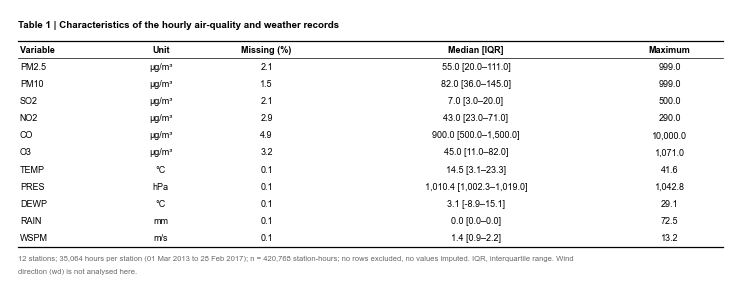

[saved] table1_data (11 rows)


In [7]:
rows = []
for v in ["PM2.5"] + VARS:
    s = df[v]
    q1, med, q3 = s.quantile([.25, .5, .75])
    rows.append({"Variable": v, "Unit": UNITS[v], "Missing (%)": fnum(s.isna().mean() * 100, 1),
                 "Median [IQR]": f"{fnum(med, 1)} [{fnum(q1, 1)}–{fnum(q3, 1)}]", "Maximum": fnum(s.max(), 1)})
t1 = pd.DataFrame(rows)
save_table(t1, "table1_data", "Table 1 | Characteristics of the hourly air-quality and weather records",
           f"{N_ST} stations; {N_H:,} hours per station ({grid[0]:%d %b %Y} to {grid[-1]:%d %b %Y}); n = {len(df):,} station-hours; "
           f"no rows excluded, no values imputed. IQR, interquartile range. Wind direction (wd) is not analysed here.")

## 2. RQ1 – Descriptive Analysis: When and Where Are PM2.5
## Levels High, and What Do Pollution Episodes Look Like?

In [8]:
def _runs(mask):
    m = np.concatenate([[False], np.asarray(mask, bool), [False]]).astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))
 
def find_episodes(s, thr=THR, min_len=MIN_LEN, max_gap=MAX_GAP):
    """Run of hours with PM2.5 > thr lasting >= min_len h; two runs separated only by missing data (<= max_gap h) are merged."""
    idx, above = s.index, (s > thr).values
    state = above.copy()
    for a, b in _runs(s.isna().values):
        if (b - a) <= max_gap and a > 0 and b < len(s) and above[a - 1] and above[b]:
            state[a:b] = True
    out = []
    for a, b in _runs(state):
        if b - a >= min_len:
            seg = s.iloc[a:b]
            out.append({"start": idx[a], "end": idx[b - 1], "duration_h": b - a, "peak": seg.max(),
                        "start_month": idx[a].month, "start_hour": idx[a].hour})
    return pd.DataFrame(out)
 
ep = find_episodes(pm_net)                                          # regional episodes (RQ1)
ep["tier"] = pd.cut(ep["peak"], [0, 150, 250, np.inf], right=False, labels=["Peak < 150", "Peak 150–250", "Peak ≥ 250"])
TIERS = ["Peak < 150", "Peak 150–250", "Peak ≥ 250"]
cold = [10, 11, 12, 1, 2, 3]
key(f"RQ1 episodes (regional, > {THR}, >= {MIN_LEN} h, gap <= {MAX_GAP} h): n = {len(ep)}; median duration {ep['duration_h'].median():.0f} h; "
    f"P90 {ep['duration_h'].quantile(.9):.0f} h; max {ep['duration_h'].max()} h; started Oct–Mar {ep['start_month'].isin(cold).mean()*100:.0f}%")

RQ1 episodes (regional, > 75, >= 6 h, gap <= 3 h): n = 463; median duration 19 h; P90 66 h; max 139 h; started Oct–Mar 49%


In [9]:
def pstats(g):
    return pd.Series({"mean": g.mean(), "median": g.median(), "P90": g.quantile(.9)})
by_month = obs.groupby("month")["PM2.5"].apply(pstats).unstack()
hour_season = obs.pivot_table(index="hour", columns="season", values="PM2.5", aggfunc="mean", observed=True)[SEASONS]
 
# station difference from the 12-station mean (daily means), 95% block-bootstrap CI
daily = pm.resample("D").mean()
d_net = daily.sub(daily.mean(axis=1), axis=0)
rng = np.random.default_rng(SEED)
def block_ci(x, block=BOOT_BLOCK_DAYS, B=BOOT_B):
    x = x.dropna().to_numpy(); n = len(x); nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(B, nb))
    idx = (starts[:, :, None] + np.arange(block)).reshape(B, -1)[:, :n]
    return np.percentile(x[idx].mean(axis=1), [2.5, 97.5])
sd = pd.DataFrame([(s, d_net[s].mean(), *block_ci(d_net[s])) for s in STATIONS], columns=["station", "diff", "lo", "hi"]).set_index("station")
sd["mean"] = obs.groupby("station")["PM2.5"].mean()
sd = sd.sort_values("diff")
r_st = pm.corr().to_numpy()[np.triu_indices(N_ST, 1)]
key(f"RQ1 months: highest mean {MONTHS[by_month['mean'].idxmax()-1]} ({by_month['mean'].max():.0f}), lowest {MONTHS[by_month['mean'].idxmin()-1]} ({by_month['mean'].min():.0f}) µg/m3; "
    f"highest hour (all seasons) {int(hour_season.mean(axis=1).idxmax())}:00, lowest {int(hour_season.mean(axis=1).idxmin())}:00")
key(f"RQ1 stations: mean PM2.5 from {sd['mean'].min():.1f} ({sd['mean'].idxmin()}) to {sd['mean'].max():.1f} ({sd['mean'].idxmax()}); "
    f"pairwise hourly correlation median {np.median(r_st):.2f} (min {r_st.min():.2f})")

RQ1 months: highest mean Dec (105), lowest Aug (53) µg/m3; highest hour (all seasons) 22:00, lowest 7:00
RQ1 stations: mean PM2.5 from 66.0 (Dingling) to 86.2 (Dongsi); pairwise hourly correlation median 0.89 (min 0.78)


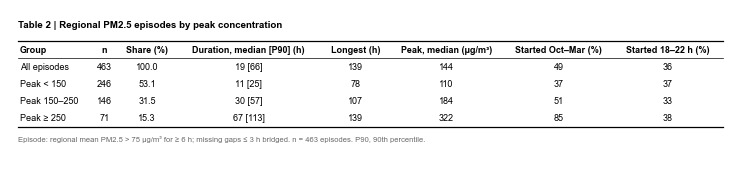

[saved] table2_episodes (4 rows)


In [10]:
def eprow(sub, label):
    return {"Group": label, "n": len(sub), "Share (%)": fnum(len(sub) / len(ep) * 100, 1),
            "Duration, median [P90] (h)": f"{sub['duration_h'].median():.0f} [{sub['duration_h'].quantile(.9):.0f}]",
            "Longest (h)": f"{sub['duration_h'].max():.0f}", "Peak, median (µg/m³)": f"{sub['peak'].median():.0f}",
            "Started Oct–Mar (%)": f"{sub['start_month'].isin(cold).mean()*100:.0f}",
            "Started 18–22 h (%)": f"{sub['start_hour'].between(18, 22).mean()*100:.0f}"}
t2 = pd.DataFrame([eprow(ep, "All episodes")] + [eprow(ep[ep["tier"] == t], t) for t in TIERS])
save_table(t2, "table2_episodes", "Table 2 | Regional PM2.5 episodes by peak concentration",
           f"Episode: regional mean PM2.5 > {THR} µg/m³ for ≥ {MIN_LEN} h; missing gaps ≤ {MAX_GAP} h bridged. n = {len(ep)} episodes. "
           f"P90, 90th percentile.")

[saved] fig2_rq1: 183 x 112 mm (limit 183 x 170 mm)


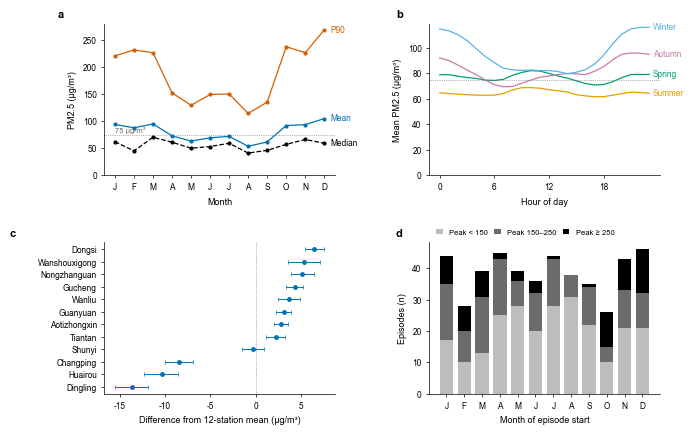

In [11]:
fig = fig_mm(W_DOUBLE, 112)
gs = grid_mm(fig, W_DOUBLE, 112, 2, 2, l=27, r=15, t=7, b=11, wsp=24, hsp=17)
# a
ax = fig.add_subplot(gs[0, 0]); panel(ax, "a", -34)
for col, c, ls in [("P90", OK["verm"], "-"), ("mean", OK["blue"], "-"), ("median", OK["black"], "--")]:
    ax.plot(by_month.index, by_month[col], color=c, ls=ls, marker="o", ms=2)
ax.axhline(THR, color=GREY, lw=0.5, ls=":"); ax.text(1, THR + 3, f"{THR} µg/m³", color=GREY, fontsize=FS - 1)
end_labels(ax, 12, [by_month[c].iloc[-1] for c in ("P90", "mean", "median")], ["P90", "Mean", "Median"],
           [OK["verm"], OK["blue"], OK["black"]], min_sep=max(by_month["P90"].max() * 0.07, 1), pad=0.3)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MONTHS]); ax.set_ylim(0, None)
ax.set_xlabel("Month"); ax.set_ylabel("PM2.5 (µg/m³)")
# b
ax = fig.add_subplot(gs[0, 1]); panel(ax, "b", -24)
for s in SEASONS:
    ax.plot(hour_season.index, hour_season[s], color=SEASON_C[s])
ax.axhline(THR, color=GREY, lw=0.5, ls=":")
end_labels(ax, 23, [hour_season[s].iloc[-1] for s in SEASONS], SEASONS, [SEASON_C[s] for s in SEASONS],
           min_sep=hour_season.max().max() * 0.07, pad=0.4)
ax.set_xticks(range(0, 24, 6)); ax.set_ylim(0, None); ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean PM2.5 (µg/m³)")
# c: every station as a point with its 95% CI
ax = fig.add_subplot(gs[1, 0]); panel(ax, "c", -68)
y = np.arange(N_ST)
ax.errorbar(sd["diff"], y, xerr=[sd["diff"] - sd["lo"], sd["hi"] - sd["diff"]], fmt="o", ms=2.5, color=OK["blue"],
            ecolor=OK["blue"], elinewidth=0.7, capsize=1.2, capthick=0.5)
ax.axvline(0, color=GREY, lw=0.5, ls=":"); ax.set_yticks(y); ax.set_yticklabels(sd.index)
ax.set_xlabel("Difference from 12-station mean (µg/m³)")
# d
ax = fig.add_subplot(gs[1, 1]); panel(ax, "d", -24)
mt = pd.crosstab(ep["start_month"], ep["tier"]).reindex(index=range(1, 13), columns=TIERS, fill_value=0)
tier_c = [LGREY, GREY, OK["black"]]; bottom = np.zeros(12)     # severity = grey scale, no clash with season colours
for t, c in zip(TIERS, tier_c):
    ax.bar(range(1, 13), mt[t], bottom=bottom, color=c, width=0.75, label=t, lw=0); bottom += mt[t].to_numpy()
ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MONTHS]); ax.set_xlabel("Month of episode start")
ax.set_ylabel("Episodes (n)"); ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=0.9, columnspacing=0.8, fontsize=FS - 1)
save_fig(fig, "fig2_rq1")
top_m, bot_m = MONTHS[by_month["mean"].idxmax() - 1], MONTHS[by_month["mean"].idxmin() - 1]
spm = sd["mean"]; per_m = mt.sum(axis=1)
CAPS["Fig. 2"] = (
    f"Fig. 2 | PM2.5 is highest in {top_m} ({by_month['mean'].max():.0f} µg/m³) and lowest in {bot_m} "
    f"({by_month['mean'].min():.0f}); station means span {spm.max() - spm.min():.0f} µg/m³ "
    f"({spm.idxmin()} {spm.min():.0f} to {spm.idxmax()} {spm.max():.0f}); episodes start in every month "
    f"({per_m.min()}–{per_m.max()} per month). "
    f"a, PM2.5 by month (12 stations pooled; dotted line, {THR} µg/m³ threshold). b, mean PM2.5 by hour and season. "
    f"c, station minus 12-station mean of daily PM2.5; points, mean; bars, 95% CI (block bootstrap, "
    f"{BOOT_BLOCK_DAYS}-day blocks, {BOOT_B} resamples). "
    f"d, start month of the {len(ep)} regional episodes by peak PM2.5 (µg/m³). "
    f"n = {len(obs):,} station-hours, {N_ST} stations. P90, 90th percentile.")

## 3. RQ2 – Explanatory Analysis: Which Variables Are Associated with PM2.5?

In [12]:
def rbc(hi, lo):
    """Rank-biserial correlation (= 2*AUC - 1) of hi vs lo; NaN if a group has < MIN_STRATUM values."""
    a, b = hi.dropna().to_numpy(), lo.dropna().to_numpy()
    if len(a) < MIN_STRATUM or len(b) < MIN_STRATUM:
        return np.nan
    r = rankdata(np.concatenate([a, b])); u = r[:len(a)].sum() - len(a) * (len(a) + 1) / 2
    return 2 * u / (len(a) * len(b)) - 1
 
def effect_label(r):
    a = abs(r); return "negligible" if a < .1 else "small" if a < .3 else "medium" if a < .5 else "large"
 
spear = obs[["PM2.5"] + VARS].corr(method="spearman")["PM2.5"].drop("PM2.5")
sp_st = pd.DataFrame({s: g[["PM2.5"] + VARS].corr(method="spearman")["PM2.5"].drop("PM2.5") for s, g in obs.groupby("station")}).loc[VARS]
hi_all, lo_all = obs[obs["is_high"]], obs[~obs["is_high"]]
rb = pd.Series({v: rbc(hi_all[v], lo_all[v]) for v in VARS})
rb_p = pd.Series({v: stats.mannwhitneyu(hi_all[v].dropna(), lo_all[v].dropna(), method="asymptotic").pvalue for v in VARS})
rb_st = pd.DataFrame({s: {v: rbc(g.loc[g["is_high"], v], g.loc[~g["is_high"], v]) for v in VARS} for s, g in obs.groupby("station")}).loc[VARS]
same_sign = {v: int((np.sign(sp_st.loc[v]) == np.sign(spear[v])).sum()) for v in VARS}
 
order_p = [v for v in spear[POLLUTANTS].abs().sort_values(ascending=False).index]
order_w = [v for v in spear[WEATHER].abs().sort_values(ascending=False).index]
ORDER = order_p + order_w
GROUP = {**{v: "Pollutant" for v in POLLUTANTS}, **{v: "Weather" for v in WEATHER}}
key("RQ2 Spearman with PM2.5: " + ", ".join(f"{v} {spear[v]:+.2f}" for v in ORDER))
key("RQ2 rank-biserial high vs non-high: " + ", ".join(f"{v} {rb[v]:+.2f} ({effect_label(rb[v])})" for v in ORDER))
key(f"RQ2 high hours n = {len(hi_all):,}, non-high n = {len(lo_all):,}; sign of Spearman equals the overall sign in "
    + ", ".join(f"{v} {same_sign[v]}/{N_ST}" for v in ORDER))

RQ2 Spearman with PM2.5: PM10 +0.89, CO +0.84, NO2 +0.66, SO2 +0.50, O3 -0.25, WSPM -0.33, DEWP +0.24, PRES -0.07, TEMP -0.02, RAIN -0.02
RQ2 rank-biserial high vs non-high: PM10 +0.89 (large), CO +0.83 (large), NO2 +0.62 (large), SO2 +0.50 (large), O3 -0.24 (small), WSPM -0.28 (small), DEWP +0.18 (small), PRES -0.02 (negligible), TEMP -0.07 (negligible), RAIN -0.02 (negligible)
RQ2 high hours n = 161,002, non-high n = 251,027; sign of Spearman equals the overall sign in PM10 12/12, CO 12/12, NO2 12/12, SO2 12/12, O3 12/12, WSPM 12/12, DEWP 12/12, PRES 12/12, TEMP 10/12, RAIN 12/12


RQ2 lag-24 h Spearman: PM2.5 +0.36, PM10 +0.32, CO +0.33, NO2 +0.31, SO2 +0.25, O3 -0.10, WSPM -0.20, DEWP +0.04, PRES +0.09, TEMP -0.05, RAIN -0.09


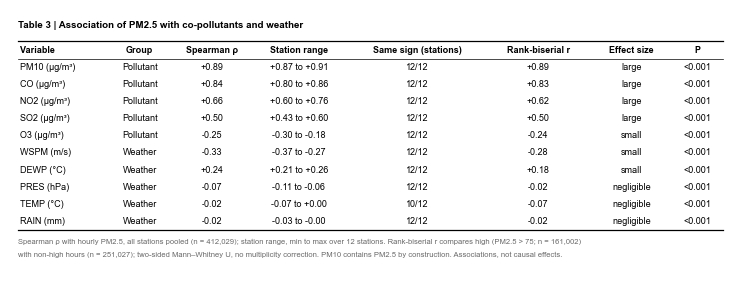

[saved] table3_rq2 (10 rows)


In [13]:
LAGS = [0, 1, 3, 6, 12, 24]
grp = df.groupby("station")
lag_rows = {}
for v in ["PM2.5"] + VARS:
    lag_rows[v] = [df["PM2.5"].corr(grp[v].shift(k), method="spearman") for k in LAGS]
lag_tab = pd.DataFrame(lag_rows, index=LAGS).T
key("RQ2 lag-24 h Spearman: " + ", ".join(f"{v} {lag_tab.loc[v, 24]:+.2f}" for v in ["PM2.5"] + ORDER))
 
# Table 3
t3 = pd.DataFrame([{
    "Variable": f"{v} ({UNITS[v]})", "Group": GROUP[v], "Spearman ρ": f"{spear[v]:+.2f}",
    "Station range": f"{sp_st.loc[v].min():+.2f} to {sp_st.loc[v].max():+.2f}",
    "Same sign (stations)": f"{same_sign[v]}/{N_ST}", "Rank-biserial r": f"{rb[v]:+.2f}",
    "Effect size": effect_label(rb[v]), "P": fp(rb_p[v])} for v in ORDER])
save_table(t3, "table3_rq2", "Table 3 | Association of PM2.5 with co-pollutants and weather",
           f"Spearman ρ with hourly PM2.5, all stations pooled (n = {len(obs):,}); station range, min to max over {N_ST} stations. "
           f"Rank-biserial r compares high (PM2.5 > {THR}; n = {len(hi_all):,}) with non-high hours (n = {len(lo_all):,}); "
           f"two-sided Mann–Whitney U, no multiplicity correction. PM10 contains PM2.5 by construction. Associations, not causal effects.")

[saved] fig3_rq2: 183 x 66 mm (limit 183 x 170 mm)


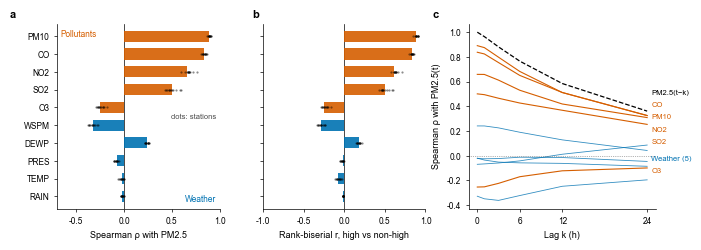

In [14]:
fig = fig_mm(W_DOUBLE, 66)
gs = grid_mm(fig, W_DOUBLE, 66, 1, 3, l=15, r=16, t=7, b=12, wsp=11, hsp=0, width_ratios=[1, 1, 1.15])
ypos = np.arange(len(ORDER))[::-1]                                  # first variable at top
gcol = lambda v: C_POLL if GROUP[v] == "Pollutant" else C_WX
for k, (ax_i, vals, st_tab, xl, letter) in enumerate([(0, spear, sp_st, "Spearman ρ with PM2.5", "a"),
                                                       (1, rb, rb_st, "Rank-biserial r, high vs non-high", "b")]):
    ax = fig.add_subplot(gs[0, ax_i]); panel(ax, letter, -34 if k == 0 else -8)
    ax.barh(ypos, [vals[v] for v in ORDER], color=[gcol(v) for v in ORDER], height=0.62, lw=0, alpha=0.9, zorder=2)
    for yv, v in zip(ypos, ORDER):                                  # every station as a grey point
        ax.scatter(st_tab.loc[v].dropna(), np.full(st_tab.loc[v].notna().sum(), yv), s=2.5, color="black", alpha=0.45, lw=0, zorder=3)
    ax.axvline(0, color="black", lw=0.5, zorder=1); ax.set_xlim(-0.7 if k == 0 else -1, 1); ax.set_ylim(-0.7, len(ORDER) - 0.3)
    ax.set_yticks(ypos); ax.set_yticklabels(ORDER if k == 0 else [])
    ax.set_xlabel(xl)
    if k == 0:
        ax.text(0.02, 0.97, "Pollutants", color=C_POLL, transform=ax.transAxes, ha="left", va="top", fontsize=FS - 0.5)
        ax.text(0.98, 0.03, "Weather", color=C_WX, transform=ax.transAxes, ha="right", va="bottom", fontsize=FS - 0.5)
        ax.text(0.98, 0.50, "dots: stations", color="black", alpha=0.7, transform=ax.transAxes, ha="right", va="center", fontsize=FS - 1)
ax = fig.add_subplot(gs[0, 2]); panel(ax, "c", -26)
for v in WEATHER:
    ax.plot(LAGS, lag_tab.loc[v], color=C_WX, lw=0.6, alpha=0.8)
for v in POLLUTANTS:
    ax.plot(LAGS, lag_tab.loc[v], color=C_POLL, lw=0.8)
ax.plot(LAGS, lag_tab.loc["PM2.5"], color="black", ls="--", lw=0.9)
ys = [lag_tab.loc[v, 24] for v in POLLUTANTS] + [lag_tab.loc["PM2.5", 24], np.mean([lag_tab.loc[v, 24] for v in WEATHER])]
end_labels(ax, 24, ys, POLLUTANTS + ["PM2.5(t−k)", "Weather (5)"], [C_POLL] * 5 + ["black", C_WX], min_sep=0.10, pad=0.6, fs=FS - 1)
ax.axhline(0, color=GREY, lw=0.5, ls=":"); ax.set_xticks([0, 6, 12, 24])
ax.set_xlabel("Lag k (h)"); ax.set_ylabel("Spearman ρ with PM2.5(t)")
save_fig(fig, "fig3_rq2")
strong = [v for v in ORDER if abs(spear[v]) >= 0.5]
CAPS["Fig. 3"] = (f"Fig. 3 | PM2.5 is most strongly associated with {', '.join(strong) if strong else 'no variable at |ρ| ≥ 0.5'}; "
                  f"weather variables are weaker (|ρ| ≤ {spear[WEATHER].abs().max():.2f}). "
                  f"a, Spearman ρ between each variable and PM2.5 (bars, pooled; dots, each of {N_ST} stations). "
                  f"b, rank-biserial correlation between high (PM2.5 > {THR}) and non-high hours "
                  f"(bars, pooled; dots, stations; positive = larger in high hours). "
                  f"c, Spearman ρ between variable at t−k and PM2.5 at t (blue, the five weather variables; dashed, PM2.5 autocorrelation). "
                  f"n = {len(obs):,} station-hours (high {len(hi_all):,}; non-high {len(lo_all):,}). "
                  f"Two-sided Mann–Whitney U for b (P-values in Table 3).")

## 4. RQ3 – Exploratory Analysis: Are There Distinct Weather
## Regimes, and Can They Distinguish Episode Onset Periods?

In [15]:
wx_ok = df[WEATHER].notna().all(axis=1)
X = StandardScaler().fit_transform(df.loc[wx_ok, WEATHER].to_numpy(float))
sil_idx = np.random.RandomState(SEED).choice(len(X), size=min(5000, len(X)), replace=False)
sweep = []
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit_predict(X)
    sweep.append({"K": k, "silhouette": silhouette_score(X[sil_idx], lab[sil_idx]), "smallest_%": np.bincount(lab).min() / len(X) * 100})
sweep = pd.DataFrame(sweep).set_index("K")
MIN_CLUSTER_PCT = 5   # chỉ xét K mà cụm nhỏ nhất có >= 5% số giờ
elig = sweep[sweep["smallest_%"] >= MIN_CLUSTER_PCT]
K = int(elig["silhouette"].idxmax())
labels = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(X)
tmp = pd.DataFrame({"c": labels, "pm": df.loc[wx_ok, "PM2.5"].to_numpy()})
order = tmp.groupby("c")["pm"].mean().sort_values(ascending=False).index.tolist()     # R1 = highest mean PM2.5
df["regime"] = np.nan
df.loc[wx_ok, "regime"] = pd.Series(labels, index=df.index[wx_ok]).map({o: i for i, o in enumerate(order)})
RN = list(range(K)); RL = [f"R{i+1}" for i in RN]
Z = pd.DataFrame(X, columns=WEATHER, index=df.index[wx_ok]).groupby(df.loc[wx_ok, "regime"].astype(int)).mean()
DESC = {"TEMP": ("cold", "warm"), "PRES": ("low-pressure", "high-pressure"), "DEWP": ("dry", "humid"), "RAIN": (None, "rainy"), "WSPM": ("calm", "windy")}
def describe(z):
    p = [DESC[v][1] if z[v] >= .5 and DESC[v][1] else DESC[v][0] for v in WEATHER if (z[v] >= .5 and DESC[v][1]) or (z[v] <= -.5 and DESC[v][0])]
    return ", ".join(p) if p else "mid-range"
reg_desc = {i: describe(Z.loc[i]) for i in RN}
 
# stability across random seeds (adjusted Rand index)
ref = df.loc[wx_ok, "regime"].astype(int).to_numpy()
ari = [adjusted_rand_score(ref, KMeans(n_clusters=K, n_init=3, random_state=s).fit_predict(X)) for s in (1, 2, 3, 4, 5)]
key(f"RQ3 K-means on 5 weather variables, n = {wx_ok.sum():,} h: silhouette by K = " + ", ".join(f"{k}:{r.silhouette:.3f}" for k, r in sweep.iterrows())
    + f"; K = {K}; smallest cluster at K = {K}: {sweep.loc[K, 'smallest_%']:.2f}%; ARI across 5 seeds {min(ari):.3f}-{max(ari):.3f}")

RQ3 K-means on 5 weather variables, n = 420,359 h: silhouette by K = 2:0.425, 3:0.430, 4:0.420, 5:0.310, 6:0.305, 7:0.309, 8:0.271; K = 2; smallest cluster at K = 2: 47.30%; ARI across 5 seeds 0.996-0.998


RQ3 station-level onsets: 6,002 (1 without weather at onset; 6,001 used); onset ratio (share of onsets / share of hours) R1 0.93 [0.86–1.00], R2 1.06 [1.00–1.13]; regime-season Cramér's V = 0.71
RQ3 PM2.5 mean by regime: R1 83.8, R2 76.2; share of hours: R1 47.5%, R2 52.5%


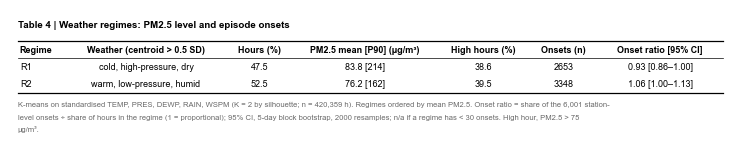

[saved] table4_rq3 (2 rows)


In [16]:
on_rows = [{"station": s, "start": r["start"]} for s in STATIONS for _, r in find_episodes(pm[s]).iterrows()]
on = pd.DataFrame(on_rows)
reg_wide = df.pivot(index="datetime", columns="station", values="regime")
on["regime"] = [reg_wide.at[t, s] for s, t in zip(on["station"], on["start"])]
n_on_all, n_on_nowx = len(on), int(on["regime"].isna().sum())
on = on.dropna(subset=["regime"]); on["regime"] = on["regime"].astype(int)
hrs = obs.assign(regime=df.loc[obs.index, "regime"]).dropna(subset=["regime"]); hrs["regime"] = hrs["regime"].astype(int)
t0 = df["datetime"].min()
hrs["blk"] = (hrs["datetime"] - t0).dt.days // ONSET_BLOCK_DAYS
on["blk"] = (on["start"] - t0).dt.days // ONSET_BLOCK_DAYS
nb = int(max(hrs["blk"].max(), on["blk"].max())) + 1
Hb = pd.crosstab(hrs["blk"], hrs["regime"]).reindex(index=range(nb), columns=RN, fill_value=0).to_numpy(float)
Ob = pd.crosstab(on["blk"], on["regime"]).reindex(index=range(nb), columns=RN, fill_value=0).to_numpy(float)
ratio = lambda O, H: (O / O.sum()) / (H / H.sum())
r_hat = ratio(Ob.sum(0), Hb.sum(0))
bidx = np.random.default_rng(SEED).integers(0, nb, size=(2000, nb))
boot = np.array([ratio(Ob[i].sum(0), Hb[i].sum(0)) for i in bidx])
r_lo, r_hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
 
ct = pd.crosstab(hrs["regime"], hrs["season"]).reindex(index=RN, columns=SEASONS, fill_value=0)
chi2, p_cs, dof, _ = stats.chi2_contingency(ct)
cramer = float(np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))))
comp = ct.div(ct.sum(axis=1), axis=0) * 100
g_hrs = hrs.groupby("regime")
prof = pd.DataFrame({"hours": g_hrs.size(), "pm_mean": g_hrs["PM2.5"].mean(), "pm_med": g_hrs["PM2.5"].median(),
                     "pm_p90": g_hrs["PM2.5"].quantile(.9), "high": g_hrs["is_high"].mean() * 100}).loc[RN]
prof["share"] = prof["hours"] / prof["hours"].sum() * 100
prof["onsets"] = on["regime"].value_counts().reindex(RN, fill_value=0)
MIN_EFFECT = 0.10                    # regimes 'separate' onsets only if the 95% CI excludes 1 AND |ratio - 1| >= this
MIN_ONSETS = 30                      # regime with fewer onsets: onset ratio is reported as n/a
OK_R = [i for i in RN if prof.loc[i, "onsets"] >= MIN_ONSETS]
ratio_txt = lambda i: f"{r_hat[i]:.2f} [{r_lo[i]:.2f}–{r_hi[i]:.2f}]" if i in OK_R else f"n/a (< {MIN_ONSETS} onsets)"
key(f"RQ3 station-level onsets: {n_on_all:,} ({n_on_nowx} without weather at onset; {len(on):,} used); onset ratio (share of onsets / share of hours) "
    + ", ".join(f"{RL[i]} {ratio_txt(i)}" for i in RN) + f"; regime-season Cramér's V = {cramer:.2f}")
key("RQ3 PM2.5 mean by regime: " + ", ".join(f"{RL[i]} {prof.loc[i, 'pm_mean']:.1f}" for i in RN)
    + "; share of hours: " + ", ".join(f"{RL[i]} {prof.loc[i, 'share']:.1f}%" for i in RN))
 
t4 = pd.DataFrame([{
    "Regime": RL[i], "Weather (centroid > 0.5 SD)": reg_desc[i], "Hours (%)": fnum(prof.loc[i, "share"], 1),
    "PM2.5 mean [P90] (µg/m³)": f"{prof.loc[i, 'pm_mean']:.1f} [{prof.loc[i, 'pm_p90']:.0f}]",
    "High hours (%)": fnum(prof.loc[i, "high"], 1), "Onsets (n)": int(prof.loc[i, "onsets"]),
    "Onset ratio [95% CI]": ratio_txt(i)} for i in RN])
save_table(t4, "table4_rq3", "Table 4 | Weather regimes: PM2.5 level and episode onsets",
           f"K-means on standardised TEMP, PRES, DEWP, RAIN, WSPM (K = {K} by silhouette; n = {wx_ok.sum():,} h). Regimes ordered by mean PM2.5. "
           f"Onset ratio = share of the {len(on):,} station-level onsets ÷ share of hours in the regime (1 = proportional); "
           f"95% CI, {ONSET_BLOCK_DAYS}-day block bootstrap, 2000 resamples; n/a if a regime has < {MIN_ONSETS} onsets. High hour, PM2.5 > {THR} µg/m³.")

[saved] fig4_rq3: 183 x 108 mm (limit 183 x 170 mm)


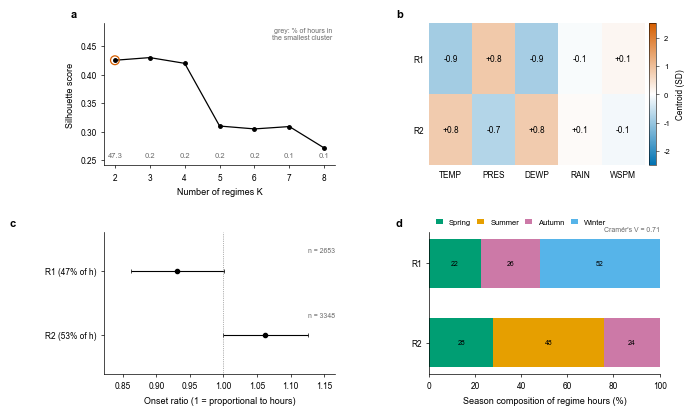

In [17]:
fig = fig_mm(W_DOUBLE, 108)
gs = grid_mm(fig, W_DOUBLE, 108, 2, 2, l=27, r=15, t=8, b=11, wsp=24, hsp=17)
ax = fig.add_subplot(gs[0, 0]); panel(ax, "a", -24)
ax.plot(sweep.index, sweep["silhouette"], color="black", marker="o", ms=2.5)
ax.scatter([K], [sweep.loc[K, "silhouette"]], s=40, facecolors="none", edgecolors=OK["verm"], lw=0.9, zorder=3)
for k, r in sweep.iterrows():      # smallest-cluster share in a row along the bottom, clear of the line
    ax.text(k, 0.07, f"{r['smallest_%']:.1f}", ha="center", va="center", fontsize=FS - 1, color=GREY, transform=ax.get_xaxis_transform())
ax.set_xlabel("Number of regimes K"); ax.set_ylabel("Silhouette score"); ax.set_ylim(sweep["silhouette"].min() - 0.03, sweep["silhouette"].max() + 0.06)
ax.text(0.99, 0.97, "grey: % of hours in\nthe smallest cluster", transform=ax.transAxes, ha="right", va="top", fontsize=FS - 1.5, color=GREY)
ax = fig.add_subplot(gs[0, 1]); panel(ax, "b", -24)
im = ax.imshow(Z.loc[RN].to_numpy(), cmap=DIV_CMAP, vmin=-2.5, vmax=2.5, aspect="auto")
for i in range(K):
    for j in range(len(WEATHER)):
        ax.text(j, i, f"{(0.0 if abs(Z.iloc[i, j]) < 0.05 else Z.iloc[i, j]):+.1f}", ha="center", va="center", fontsize=FS - 0.5)
ax.set_xticks(range(len(WEATHER))); ax.set_xticklabels(WEATHER); ax.set_yticks(range(K)); ax.set_yticklabels(RL)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0); cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02); cb.set_label("Centroid (SD)", fontsize=FS - 0.5)
cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=FS - 1, width=0.4)
ax = fig.add_subplot(gs[1, 0]); panel(ax, "c", -68)
yy = np.arange(K)[::-1]
okm = np.array([i in OK_R for i in RN])
ax.errorbar(r_hat[okm], yy[okm], xerr=[(r_hat - r_lo)[okm], (r_hi - r_hat)[okm]], fmt="o", ms=3, color="black", elinewidth=0.8, capsize=1.5, capthick=0.5)
for yv, i in zip(yy, RN):
    if i not in OK_R:
        ax.text(1.0, yv, f"n/a ({int(prof.loc[i, 'onsets'])} onsets)", ha="center", va="center", fontsize=FS - 0.5, color=GREY)
if okm.any():
    lo_, hi_ = r_lo[okm].min(), r_hi[okm].max(); pad_ = 0.15 * (hi_ - lo_ + 1e-9)
    ax.set_xlim(min(lo_ - pad_, 0.95), max(hi_ + pad_, 1.05))
else:
    ax.set_xlim(0.8, 1.2)
ax.axvline(1, color=GREY, lw=0.5, ls=":"); ax.set_yticks(yy); ax.set_yticklabels([f"{RL[i]} ({prof.loc[i, 'share']:.0f}% of h)" for i in RN])
for yv, i in zip(yy, RN):
    ax.text(1.0, yv + 0.28, f"n = {int(prof.loc[i, 'onsets'])}", transform=ax.get_yaxis_transform(), ha="right", fontsize=FS - 1.5, color=GREY, clip_on=False)
ax.set_xlabel("Onset ratio (1 = proportional to hours)"); ax.set_ylim(-0.6, K - 0.4)
ax = fig.add_subplot(gs[1, 1]); panel(ax, "d", -24)
left = np.zeros(K)
for s in SEASONS:
    ax.barh(yy, comp[s].to_numpy(), left=left, color=SEASON_C[s], height=0.62, lw=0, label=s)
    for yv, v, l0 in zip(yy, comp[s].to_numpy(), left):
        if v >= 9: ax.text(l0 + v / 2, yv, f"{v:.0f}", ha="center", va="center", fontsize=FS - 1.5, color="black")
    left += comp[s].to_numpy()
ax.set_yticks(yy); ax.set_yticklabels(RL); ax.set_xlim(0, 100); ax.set_xlabel("Season composition of regime hours (%)")
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=0.9, columnspacing=0.8, fontsize=FS - 1)
ax.text(1.0, 1.0, f"Cramér's V = {cramer:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=FS - 1.5, color=GREY)
save_fig(fig, "fig4_rq3")
sep = any(((r_lo[i] > 1) or (r_hi[i] < 1)) and abs(r_hat[i] - 1) >= MIN_EFFECT for i in OK_R)
excl = [RL[i] for i in RN if i not in OK_R]
CAPS["Fig. 4"] = (f"Fig. 4 | Weather clusters into {K} regimes that track the season (Cramér's V = {cramer:.2f}); onset ratios range from {min([r_hat[i] for i in OK_R] or [float('nan')]):.2f} to {max([r_hat[i] for i in OK_R] or [float('nan')]):.2f}"
    + (f" ({', '.join(excl)} excluded: < {MIN_ONSETS} onsets)" if excl else "") + " and "
    + (f"at least one regime has a 95% CI excluding 1 by ≥ {MIN_EFFECT:.2f}." if sep else f"no regime separates onset frequency (95% CIs include 1 or differ from 1 by < {MIN_EFFECT:.2f}).")
    + f" a, silhouette score by K (circle, selected K = {K}; grey, % of hours in the smallest cluster). b, regime centroids of the five standardised weather variables (SD). "
    f"c, onset ratio per regime (point, estimate; bars, 95% CI from {ONSET_BLOCK_DAYS}-day block bootstrap; n, onsets). d, season composition of each regime (% of hours). "
    f"n = {wx_ok.sum():,} h for clustering; {len(on):,} station-level onsets. Regimes ordered by mean PM2.5 (R1 highest).")

[saved] fig1_workflow: 183 x 84 mm (limit 183 x 170 mm)


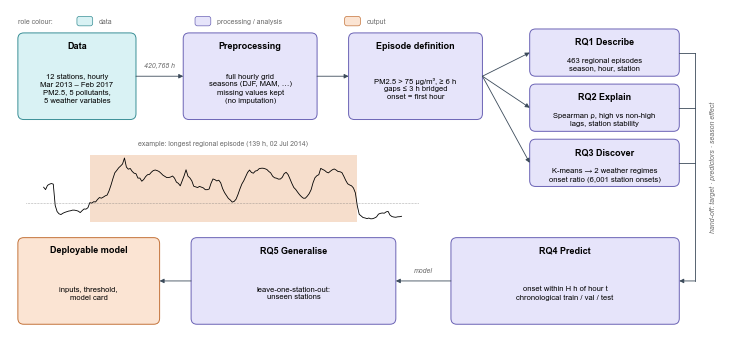

In [18]:
Hc = 84
fig = fig_mm(W_DOUBLE, Hc)
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W_DOUBLE); ax.set_ylim(0, Hc); ax.axis("off")
COL = {"data": ("#d9f2f4", "#3a8f96"), "learn": ("#e6e4fa", "#6b63b5"), "out": ("#fbe4d3", "#c4733a")}
def box(x, y, w, h, title, sub, role, dashed=False):
    fc, ec = COL[role]
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.5", fc=fc, ec=ec, lw=0.7, ls="--" if dashed else "-"))
    ax.text(x + w / 2, y + h - 3.2, title, ha="center", va="center", fontsize=FS, fontweight="bold")
    ax.text(x + w / 2, y + (h - 6) / 2, sub, ha="center", va="center", fontsize=FS - 1, linespacing=1.35)
def arrow(x0, y0, x1, y1, label=""):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=0.6, color="#3b4a5a", shrinkA=0, shrinkB=0))
    if label: ax.text((x0 + x1) / 2, max(y0, y1) + 2.2, label, ha="center", fontsize=FS - 1.5, color=GREY, style="italic")
Hh, yt = 22, 56
box(2, yt, 30, Hh, "Data", f"{N_ST} stations, hourly\n{grid[0]:%b %Y} – {grid[-1]:%b %Y}\nPM2.5, 5 pollutants,\n5 weather variables", "data")
box(44, yt, 34, Hh, "Preprocessing", "full hourly grid\nseasons (DJF, MAM, …)\nmissing values kept\n(no imputation)", "learn")
box(86, yt, 34, Hh, "Episode definition", f"PM2.5 > {THR} µg/m³, ≥ {MIN_LEN} h\ngaps ≤ {MAX_GAP} h bridged\nonset = first hour", "learn")
arrow(32, yt + 11, 44, yt + 11, f"{len(df):,} h"); arrow(78, yt + 11, 86, yt + 11)
rq = [("RQ1 Describe", f"{len(ep)} regional episodes\nseason, hour, station", yt + 11),
      ("RQ2 Explain", "Spearman ρ, high vs non-high\nlags, station stability", yt - 3),
      ("RQ3 Discover", f"K-means → {K} weather regimes\nonset ratio ({len(on):,} station onsets)", yt - 17)]
for t, s, y in rq:
    box(132, y, 38, 12, t, s, "learn")
    arrow(120, yt + 11, 132, y + 6)
    ax.plot([170, 174], [y + 6, y + 6], color="#3b4a5a", lw=0.6)   # collect RQ1-RQ3 outputs
ax.plot([174, 174], [rq[0][2] + 6, 15], color="#3b4a5a", lw=0.6)
ax.text(178.5, 44, "hand-off: target · predictors · season effect", rotation=90, ha="center", va="center",
        fontsize=FS - 1.5, color=GREY, style="italic")
box(112, 4, 58, 22, "RQ4 Predict", "onset within H h of hour t\nchronological train / val / test", "learn")
box(46, 4, 52, 22, "RQ5 Generalise", "leave-one-station-out:\nunseen stations", "learn")
box(2, 4, 36, 22, "Deployable model", "inputs, threshold,\nmodel card", "out")
arrow(174, 15, 170, 15); arrow(112, 15, 98, 15, "model"); arrow(46, 15, 38, 15)
# real example: the longest regional episode ± 24 h
e = ep.sort_values("duration_h", ascending=False).iloc[0]
w0, w1 = e["start"] - pd.Timedelta(hours=24), e["end"] + pd.Timedelta(hours=24)
seg = pm_net.loc[w0:w1]
ins = fig.add_axes([4 / W_DOUBLE, 30 / Hc, 100 / W_DOUBLE, 17 / Hc]); ins.patch.set_alpha(0)
ins.plot(np.arange(len(seg)), seg.values, color="black", lw=0.6); ins.axhline(THR, color=GREY, lw=0.4, ls=":")
ins.axvspan(24, 24 + e["duration_h"], color=OK["verm"], alpha=0.2, lw=0)
ins.set_xticks([]); ins.set_yticks([]); [s.set_visible(False) for s in ins.spines.values()]
ax.text(54, 49.5, f"example: longest regional episode ({e['duration_h']} h, {e['start']:%d %b %Y})", ha="center", fontsize=FS - 1.5, color=GREY)
ax.text(2, 81, "role colour:", fontsize=FS - 1.5, color=GREY, va="center")
for k, (lab, r) in enumerate([("data", "data"), ("processing / analysis", "learn"), ("output", "out")]):
    xx = 17 + k * 30 + (0 if k < 2 else 8)
    ax.add_patch(FancyBboxPatch((xx, 79.8), 4, 2.4, boxstyle="round,pad=0,rounding_size=0.6", fc=COL[r][0], ec=COL[r][1], lw=0.5))
    ax.text(xx + 5.5, 81, lab, fontsize=FS - 1.5, color=GREY, va="center")
save_fig(fig, "fig1_workflow")
CAPS["Fig. 1"] = (f"Fig. 1 | Analysis workflow from the hourly records to RQ1–RQ3, and how their results feed onset prediction (RQ4) and transfer to unseen stations (RQ5). "
    f"Arrow label, number of station-hours; RQ1–RQ3 hand over the prediction target (station-level onsets; RQ4 keeps only those not adjacent to missing data), "
    f"the candidate predictors and the season effect. "
    f"Inset, the longest regional episode ({e['duration_h']} h, from {e['start']:%d %b %Y}) with 24 h either side; dotted line, {THR} µg/m³ threshold, shaded band, episode "
    f"(chosen by rule: longest, not by taste). n = {len(df):,} station-hours, {N_ST} stations.")

In [19]:
with open(os.path.join(OUT_DIR, "captions.md"), "w", encoding="utf-8") as f:
    f.write("# Figure captions (first sentence = finding; check every claim against the figure before submitting)\n\n")
    for k in ["Fig. 1", "Fig. 2", "Fig. 3", "Fig. 4"]:
        f.write(CAPS[k] + "\n\n")
with open(os.path.join(OUT_DIR, "key_numbers.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(KEY) + "\n")
print("\nDone. Font used:", FONT, "| outputs in", os.path.abspath(OUT_DIR))


Done. Font used: Arial | outputs in /Users/nguyennguyetanh/outputs


In [20]:
import os, glob, json, time, pickle, warnings, textwrap
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from sklearn.metrics import average_precision_score
import lightgbm as lgb
warnings.filterwarnings("ignore")

DATA_DIR, OUT_DIR, SHOW = ".", "outputs", True
QUICK = os.environ.get("RQ45_QUICK") == "1"          # chạy thử nhanh (chỉ để kiểm tra mã)
SEED = 42
CFG = dict(THETA=75, N=6, G=3, H_LIST=[1, 3, 6, 12, 24], H_MAIN=6)
SPLITS = {"train": ("2013-03-01 00:00", "2015-02-28 23:00"), "gap1": ("2015-03-01 00:00", "2015-03-07 23:00"),
          "val": ("2015-03-08 00:00", "2016-02-29 23:00"), "gap2": ("2016-03-01 00:00", "2016-03-07 23:00"),
          "test": ("2016-03-08 00:00", "2017-02-28 23:00")}
# Tham số TRIỂN KHAI: là giả định của bên vận hành, không phải kết quả thực nghiệm (xem mục 8)
DEPLOY = dict(BUDGET=12,      # tối đa 12 cảnh báo giả / trạm / 30 ngày (~1 cảnh báo giả mỗi 2.5 ngày)
              MIN_LEAD=3,     # cảnh báo chỉ "dùng được" nếu báo trước >= 3 giờ
              EPS=0.02,       # chênh recall <= 2 điểm % thì ưu tiên mô hình đơn giản hơn
              H_CAND=[6, 12], # tầm báo trước ứng viên: 6 h (quyết định trong ngày), 12 h (qua đêm)
              R_COST=10)      # chi phí bỏ sót : cảnh báo giả = 10 : 1 (chỉ dùng cho chỉ số phụ)
NBOOT, BLOCK_DAYS = (60 if QUICK else 2000), 5
POLLUTANTS = ["PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
TARGET = "PM2.5"
FULL_START, FULL_END = pd.Timestamp("2013-03-01 00:00"), pd.Timestamp("2017-02-28 23:00")
FULL_IDX = pd.date_range(FULL_START, FULL_END, freq="h")

OK = dict(black="#000000", orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442",
          blue="#0072B2", verm="#D55E00", purple="#CC79A7")
C_POLL, C_WX = OK["verm"], OK["blue"]                      # one object = one colour across the paper
SEASON_C = {"Spring": OK["green"], "Summer": OK["orange"], "Autumn": OK["purple"], "Winter": OK["sky"]}
GREY, LGREY = "#6b6b6b", "#bdbdbd"
DIV_CMAP = mpl.colors.LinearSegmentedColormap.from_list("blue_white_verm", [OK["blue"], "#ffffff", OK["verm"]])

_avail = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ["Arial", "Helvetica", "Liberation Sans", "FreeSans", "DejaVu Sans"] if f in _avail), "DejaVu Sans")
FS = 6.5
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "font.size": FS,
    "axes.labelsize": FS, "axes.titlesize": FS, "xtick.labelsize": FS - 0.5, "ytick.labelsize": FS - 0.5,
    "legend.fontsize": FS - 0.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "lines.linewidth": 0.9, "legend.frameon": False, "axes.unicode_minus": False,
    "pdf.fonttype": 42, "svg.fonttype": "none", "figure.dpi": 100, "savefig.dpi": 300,
})
os.makedirs(OUT_DIR, exist_ok=True)
MM = 1 / 25.4
W_DOUBLE = 183                                              # mm, two-column width

def fig_mm(w, h):
    return plt.figure(figsize=(w * MM, h * MM))

def grid_mm(fig, W, H, nrows, ncols, l, r, t, b, wsp, hsp, **kw):
    """Gridspec whose margins and gaps are given in mm."""
    aw = (W - l - r - wsp * (ncols - 1)) / ncols
    ah = (H - t - b - hsp * (nrows - 1)) / nrows
    return fig.add_gridspec(nrows, ncols, left=l / W, right=1 - r / W, top=1 - t / H, bottom=b / H,
                            wspace=wsp / aw, hspace=hsp / ah, **kw)

def plab(ax, letter, dx=-22, dy=3):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy), textcoords="offset points",
                fontsize=8, fontweight="bold", ha="left", va="bottom")

def spread(ys, min_sep):
    """Separate labels by at least min_sep; each pushed run is re-centred on its original centre."""
    ys = np.asarray(ys, float); order = np.argsort(ys); y = ys[order]; pos = y.copy()
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + min_sep)
    i = 0
    while i < len(pos):
        j = i
        while j + 1 < len(pos) and pos[j + 1] - pos[j] <= min_sep + 1e-9:
            j += 1
        pos[i:j + 1] += y[i:j + 1].mean() - pos[i:j + 1].mean()
        i = j + 1
    out = np.empty_like(pos); out[order] = pos
    return out

def end_labels(ax, x, ys, names, colors, min_sep, pad=0.4, fs=FS - 0.5):
    for y, n, c in zip(spread(ys, min_sep), names, colors):
        ax.text(x + pad, y, n, color=c, va="center", ha="left", fontsize=fs, clip_on=False)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"))
    w, h = fig.get_size_inches() * 25.4
    print(f"[saved] {name}: {w:.0f} x {h:.0f} mm (limit 183 x 170 mm)")
    (plt.show() if SHOW else plt.close(fig))

def fnum(x, d=1):
    return "–" if pd.isna(x) else f"{x:,.{d}f}"

def fp(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

In [21]:
def save_table(tab, name, title, note="", first_left=True):
    tab = tab.copy()
    tab.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False)
    esc = lambda s: str(s).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&")
    cols = list(tab.columns)
    with open(os.path.join(OUT_DIR, f"{name}.tex"), "w", encoding="utf-8") as f:
        f.write("\\begin{table}[t]\n\\centering\n\\caption{" + esc(title) + "}\n")
        f.write("\\begin{tabular}{" + "l" + "c" * (len(cols) - 1) + "}\n\\toprule\n")
        f.write(" & ".join(esc(c) for c in cols) + " \\\\\n\\midrule\n")
        for _, r in tab.iterrows():
            f.write(" & ".join(esc(v) for v in r.values) + " \\\\\n")
        f.write("\\bottomrule\n\\end{tabular}\n")
        if note:
            f.write("\\\\[2pt]{\\footnotesize " + esc(note) + "}\n")
        f.write("\\end{table}\n")
    # PDF rendering at 183 mm, shrinking the font if the columns do not fit
    cells = [cols] + tab.astype(str).values.tolist()
    maxlen = [max(len(str(c[j])) for c in cells) for j in range(len(cols))]
    fs = FS
    while fs > 5 and (sum(maxlen) + 2.2 * len(cols)) * fs * 0.52 * 0.3528 > W_DOUBLE - 4:
        fs -= 0.25
    cw = np.array([m + 2.2 for m in maxlen], float); cw = cw / cw.sum() * (W_DOUBLE - 4)
    row_h, n = fs * 0.3528 * 1.9, len(cells)
    note_lines = textwrap.wrap(note, 165) if note else []
    H = 10 + row_h * n + 4 + 3.2 * len(note_lines)
    fig = fig_mm(W_DOUBLE, H); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W_DOUBLE); ax.set_ylim(0, H); ax.axis("off")
    ax.text(2, H - 4, title, fontsize=fs + 0.5, fontweight="bold", va="center", ha="left")
    y0 = H - 8; xs = 2 + np.concatenate([[0], np.cumsum(cw)])
    ax.plot([2, W_DOUBLE - 2], [y0, y0], color="black", lw=0.9)
    for i, row in enumerate(cells):
        yc = y0 - row_h * (i + 0.5)
        for j, v in enumerate(row):
            left = (j == 0 and first_left)
            ax.text(xs[j] + (0.5 if left else cw[j] / 2), yc, v, fontsize=fs, va="center", ha="left" if left else "center",
                    fontweight="bold" if i == 0 else "normal")
        if i == 0:
            ax.plot([2, W_DOUBLE - 2], [y0 - row_h] * 2, color="black", lw=0.5)
    ax.plot([2, W_DOUBLE - 2], [y0 - row_h * n] * 2, color="black", lw=0.9)
    for k, ln in enumerate(note_lines):
        ax.text(2, y0 - row_h * n - 3 - 3.2 * k, ln, fontsize=fs - 1, color=GREY, va="center", ha="left")
    fig.savefig(os.path.join(OUT_DIR, f"{name}.pdf")); fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), dpi=200)
    (plt.show() if SHOW else plt.close(fig))
    print(f"[saved] {name} ({len(tab)} rows)")
 
KEY, CAPS = [], {}                                       # key numbers and captions collected along the way
MODEL_ORDER = ["climatology", "pm25_only", "GB_A", "GB_W", "GB_B", "GB_PW", "GB_C"]
LAB = {"climatology": "Climatology", "pm25_only": "PM2.5-only", "GB_A": "A: pollutants", "GB_W": "W: weather",
       "GB_B": "B: A + W", "GB_PW": "PW: W + PM2.5", "GB_C": "C: B + PM2.5"}
MC = {"climatology": GREY, "pm25_only": OK["orange"], "GB_A": C_POLL, "GB_W": C_WX,
      "GB_B": OK["purple"], "GB_PW": OK["green"], "GB_C": OK["black"]}
def ci_str(v, d=2):
    lo, hi = np.nanpercentile(v[1:], [2.5, 97.5]); return f"{v[0]:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"
def ci(v): return np.nanpercentile(v[1:], [2.5, 97.5])

## 5.1. Data: Continuous Hourly Time Series and Train/Validation/Test Splits

In [22]:
STATION_NAMES = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng",
                 "Huairou", "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
datasets = {n: pd.read_csv(os.path.join(DATA_DIR, f"{n}.csv")) for n in STATION_NAMES}
for n, d in datasets.items():
    assert {"year", "month", "day", "hour", TARGET} <= set(d.columns), f"{n}: thiếu cột"
assert len(datasets) == 12

def prepare_station(df, name):
    d = df.copy(); d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]])
    d = d.drop_duplicates("datetime").set_index("datetime").sort_index().reindex(FULL_IDX)   # giờ vắng -> NaN rõ ràng
    d.index.name = "datetime"; d["station"] = name
    s = pd.Series("none", index=d.index)
    for k, (a, b) in SPLITS.items(): s[(d.index >= pd.Timestamp(a)) & (d.index <= pd.Timestamp(b))] = k
    d["split"] = s.values
    return d
panel = {n: prepare_station(d, n) for n, d in datasets.items()}
STATIONS = list(panel); N_ST = len(STATIONS)
SID = {n: i for i, n in enumerate(STATIONS)}; SID_NAME = {i: n for n, i in SID.items()}
print(N_ST, "trạm;", len(FULL_IDX), "giờ mỗi trạm;", "PM2.5 thiếu (%):",
      round(100 * np.mean([d[TARGET].isna().mean() for d in panel.values()]), 2))

12 trạm; 35064 giờ mỗi trạm; PM2.5 thiếu (%): 2.08


## 5.2.  Episodes, Onsets, and (y_H) Labels (Consistent with RQ1–RQ3; Episodes Potentially Affected by Missing Data Are Excluded from Labeling)

In [23]:
def find_episodes(pm, theta, N, G):
    """Trả về (bảng episode, mảng trạng thái giờ). Chạy trên chuỗi liên tục của một trạm."""
    s = np.where(pm.isna().values, -1, (pm.values > theta).astype(int))   # 1 vượt, 0 sạch, -1 thiếu
    n = len(s)
 
    # (a) các đoạn vượt ngưỡng liên tiếp (tối đại)
    runs, i = [], 0
    while i < n:
        if s[i] == 1:
            j = i
            while j + 1 < n and s[j + 1] == 1:
                j += 1
            runs.append((i, j)); i = j + 1
        else:
            i += 1
 
    # (b) gộp: khoảng trống <= G và toàn bộ giờ trống đều quan sát được (s == 0)
    segs = []
    if runs:
        ca, cb = runs[0]
        for a, b in runs[1:]:
            gap = a - cb - 1
            if gap <= G and (s[cb + 1:a] == 0).all():
                cb = b
            else:
                segs.append((ca, cb)); ca, cb = a, b
        segs.append((ca, cb))
 
    # (c) phân loại
    def unc_left(a):    # có NaN/biên trong G+1 giờ trước a => onset thật có thể sớm hơn
        lo = a - G - 1
        return lo < 0 or (s[lo:a] == -1).any()
    def unc_right(b):   # có NaN/biên trong G+1 giờ sau b => độ dài thật chưa rõ
        hi = b + G + 1
        return hi > n - 1 or (s[b + 1:hi + 1] == -1).any()
 
    rows = []
    for a, b in segs:
        L = b - a + 1
        lu, ru = unc_left(a), unc_right(b)
        if lu:           status = "uncertain"
        elif L >= N:     status = "valid"
        elif ru:         status = "uncertain"
        else:            status = "invalid"      # đoạn ngắn, hai phía rõ ràng => không phải episode
        rows.append((a, b, L, status))
    ep = pd.DataFrame(rows, columns=["a", "b", "length", "status"])
    return ep, s

In [24]:
def window_sum(x, H):
    """Tổng x trên (t, t+H] cho mọi t. NaN nếu cửa sổ vượt quá cuối chuỗi."""
    n = len(x)
    cs = np.concatenate([[0], np.cumsum(x)])
    t = np.arange(n)
    out = np.full(n, np.nan)
    ok = t + H <= n - 1
    out[ok] = cs[t[ok] + H + 1] - cs[t[ok] + 1]
    return out
 
def build_labels(d, cfg):
    pm = d[TARGET]
    ep, s = find_episodes(pm, cfg["THETA"], cfg["N"], cfg["G"])
    n = len(s)
 
    onset_valid = np.zeros(n, dtype=int)
    onset_unc   = np.zeros(n, dtype=int)
    in_span     = np.zeros(n, dtype=bool)
    for a, b, L, st in ep.itertuples(index=False):
        if st == "valid":
            onset_valid[a] = 1; in_span[a:b + 1] = True
        elif st == "uncertain":
            onset_unc[a] = 1;   in_span[a:b + 1] = True
 
    out = pd.DataFrame(index=d.index)
    out["state"]       = s
    out["onset_valid"] = onset_valid
    out["onset_unc"]   = onset_unc
    out["in_episode"]  = in_span
    base = (s == 0) & (~in_span)          # đang sạch, quan sát được, không nằm trong episode
 
    nan_flag = (s == -1).astype(int)
    for H in cfg["H_LIST"]:
        w_nan = window_sum(nan_flag, H)
        w_unc = window_sum(onset_unc, H)
        w_on  = window_sum(onset_valid, H)
        elig = base & ~np.isnan(w_nan) & (w_nan == 0) & (w_unc == 0)
        out[f"elig_{H}"] = elig
        out[f"y_{H}"]    = np.where(elig, (w_on > 0).astype(int), -1).astype(np.int8)   # -1: không dùng
    ep["onset_time"] = d.index[ep["a"].values]
    ep["end_time"]   = d.index[ep["b"].values]
    return out, ep
 
lab, episodes = {}, {}
for name, d in panel.items():
    lab[name], episodes[name] = build_labels(d, CFG)
    lab[name]["split"] = d["split"].values
    lab[name]["station"] = name
    episodes[name]["station"] = name
    episodes[name]["split"] = d["split"].values[episodes[name]["a"].values]   # giai đoạn theo giờ onset
 
# Kiểm tra logic cơ bản
for name in panel:
    ev = episodes[name]
    assert (ev.loc[ev.status == "valid", "length"] >= CFG["N"]).all()
    l = lab[name]
    for H in CFG["H_LIST"]:
        e = l[l[f"elig_{H}"]]
        assert (panel[name].loc[e.index, TARGET] <= CFG["THETA"]).all()   # mẫu đều dưới ngưỡng, không NaN
        assert (e["onset_valid"] == 0).all()                              # giờ onset không phải mẫu
print("Kiểm tra logic nhãn: OK")
 
# %%
EP = pd.concat(episodes.values(), ignore_index=True); EP = EP[EP.status == "valid"].copy()
SPLIT_START = {s: pd.Timestamp(SPLITS[s][0]) for s in ["val", "test"]}
SPLIT_DAYS = {s: (pd.Timestamp(SPLITS[s][1]) + pd.Timedelta(hours=1) - pd.Timestamp(SPLITS[s][0])) / pd.Timedelta(days=1)
              for s in ["val", "test"]}
print("Episode hợp lệ theo giai đoạn (theo giờ onset):", EP.groupby("split").size().to_dict())
print("Lưu ý: số episode ở đây (valid) nhỏ hơn số ở RQ1–RQ3 vì RQ4 loại episode có dữ liệu thiếu ở biên (uncertain).")

Kiểm tra logic nhãn: OK
Episode hợp lệ theo giai đoạn (theo giờ onset): {'gap1': 21, 'gap2': 19, 'test': 1249, 'train': 2706, 'val': 1073}
Lưu ý: số episode ở đây (valid) nhỏ hơn số ở RQ1–RQ3 vì RQ4 loại episode có dữ liệu thiếu ở biên (uncertain).


## 5.3. Past-Only Features, Feature Groups, and Modeling Scenarios

In [25]:
WD_DEG = {"N": 0, "NNE": 22.5, "NE": 45, "ENE": 67.5, "E": 90, "ESE": 112.5, "SE": 135, "SSE": 157.5,
          "S": 180, "SSW": 202.5, "SW": 225, "WSW": 247.5, "W": 270, "WNW": 292.5, "NW": 315, "NNW": 337.5}
LAGS_POLL = [1, 3, 6, 24]       # lag của pollutant (>= 1 giờ)
 
# kiểm tra giá trị hướng gió có nằm trong bảng quy đổi
wd_vals = set(pd.concat([d["wd"] for d in panel.values()]).dropna().unique())
print("Hướng gió không có trong bảng quy đổi:", wd_vals - set(WD_DEG))
 
def roll(s, w, how):
    return getattr(s.rolling(w, min_periods=w), how)()
 
def build_features(d):
    f = pd.DataFrame(index=d.index)
    # --- lịch (biết trước, không rò rỉ) ---
    hr, mo, dow = d.index.hour.values, d.index.month.values, d.index.dayofweek.values
    f["hour_sin"] = np.sin(2 * np.pi * hr / 24);       f["hour_cos"] = np.cos(2 * np.pi * hr / 24)
    f["month_sin"] = np.sin(2 * np.pi * (mo - 1) / 12); f["month_cos"] = np.cos(2 * np.pi * (mo - 1) / 12)
    f["is_weekend"] = (dow >= 5).astype(int)
 
    # --- tốc độ gió ---
    ws = d["WSPM"]
    f["ws_t"] = ws
    for k in [1, 2, 3]:
        f[f"ws_lag{k}"] = ws.shift(k)
    for w in [6, 12]:
        f[f"ws_mean{w}"] = roll(ws, w, "mean")
        f[f"ws_min{w}"]  = roll(ws, w, "min")
    f["ws_d3"] = ws - ws.shift(3)
 
    # --- hướng gió (sin/cos) + hướng trung bình trailing 6 giờ ---
    deg = d["wd"].map(WD_DEG)
    rad = np.deg2rad(deg)
    f["wd_sin"], f["wd_cos"] = np.sin(rad), np.cos(rad)
    f["wd_sin_mean6"] = roll(f["wd_sin"], 6, "mean")
    f["wd_cos_mean6"] = roll(f["wd_cos"], 6, "mean")
    f["wd_missing"] = deg.isna().astype(int)
 
    # --- nhiệt độ, áp suất: giá trị và thay đổi 3/6/24 giờ ---
    for col, tag in [("TEMP", "temp"), ("PRES", "pres")]:
        x = d[col]
        f[f"{tag}_t"] = x
        for k in [3, 6, 24]:
            f[f"{tag}_d{k}"] = x - x.shift(k)
 
    # --- nhóm mở rộng (ngoài kịch bản chính): điểm sương, mưa ---
    f["dewp_t"] = d["DEWP"]
    f["dewp_d3"] = d["DEWP"] - d["DEWP"].shift(3)
    f["dewp_d6"] = d["DEWP"] - d["DEWP"].shift(6)
    f["spread_t"] = d["TEMP"] - d["DEWP"]
    f["rain_t"] = d["RAIN"]
    f["rain_sum6"]  = roll(d["RAIN"], 6, "sum")
    f["rain_sum24"] = roll(d["RAIN"], 24, "sum")
 
    # --- pollutant trễ (không PM2.5) ---
    for p in POLLUTANTS:
        x, tag = d[p], p.lower()
        for k in LAGS_POLL:
            f[f"{tag}_lag{k}"] = x.shift(k)
        f[f"{tag}_mean6_l1"] = roll(x.shift(1), 6, "mean")      # trung bình 6 giờ kết thúc ở t-1
 
    # --- PM2.5 (chỉ dùng cho C và baseline) ---
    pm = d[TARGET]
    f["pm25_t"] = pm
    f["pm25_lag1"], f["pm25_lag3"], f["pm25_lag6"] = pm.shift(1), pm.shift(3), pm.shift(6)
    f["pm25_d1"] = pm - pm.shift(1)
    f["pm25_d3"] = pm - pm.shift(3)
    return f
 
# %%
tmpl = build_features(panel[STATIONS[0]])
TOKEN2GROUP = {"hour": "calendar", "month": "calendar", "is": "calendar", "ws": "wind_speed", "wd": "wind_dir",
               "temp": "temp", "pres": "pres", "dewp": "dewp", "spread": "dewp", "rain": "rain", "pm25": "pm25",
               "pm10": "pollutant", "so2": "pollutant", "no2": "pollutant", "co": "pollutant", "o3": "pollutant"}
GROUPS = {}
for c in tmpl.columns: GROUPS.setdefault(TOKEN2GROUP[c.split("_")[0]], []).append(c)
BASE_PM25_COLS = ["pm25_t", "pm25_lag1"]
W_COLS = GROUPS["wind_speed"] + GROUPS["wind_dir"] + GROUPS["temp"] + GROUPS["pres"] + GROUPS["calendar"]
# KHÔNG có station_id: mô hình phải mang sang được trạm mới (kiểm chứng lại ở mục 10)
SCEN = {"A": GROUPS["pollutant"], "W": W_COLS, "B": GROUPS["pollutant"] + W_COLS,
        "C": GROUPS["pollutant"] + W_COLS + GROUPS["pm25"], "PW": W_COLS + BASE_PM25_COLS}
FEATS = {"pm25_only": BASE_PM25_COLS, "GB_A": SCEN["A"], "GB_W": SCEN["W"], "GB_B": SCEN["B"],
         "GB_C": SCEN["C"], "GB_PW": SCEN["PW"]}
assert not any(c.startswith("pm25") for c in SCEN["B"]) and "station_id" not in SCEN["C"]
print({k: len(v) for k, v in FEATS.items()})

Hướng gió không có trong bảng quy đổi: set()
{'pm25_only': 2, 'GB_A': 25, 'GB_W': 27, 'GB_B': 52, 'GB_C': 58, 'GB_PW': 29}


In [26]:
frames = []
for sid, (name, d) in enumerate(panel.items()):
    f = build_features(d)
    f["station"], f["station_id"] = name, sid
    f["split"] = d["split"].values
    f["hour"], f["month"] = d.index.hour, d.index.month       # chỉ dùng cho climatology (không phải đặc trưng mô hình)
    for H in CFG["H_LIST"]:
        f[f"elig_{H}"] = lab[name][f"elig_{H}"].values
        f[f"y_{H}"] = lab[name][f"y_{H}"].values
    frames.append(f)
 
data = pd.concat(frames)
data.index.name = "datetime"
data = data.reset_index()
data = data[data["split"].isin(["train", "val", "test"])].reset_index(drop=True)   # bỏ hai khoảng đệm
print("Bảng dữ liệu:", data.shape)
print(data.groupby("split").size())

Bảng dữ liệu: (416736, 81)
split
test     103104
train    210240
val      103392
dtype: int64


In [27]:
# (a) lag đúng chiều: đặc trưng tại t phải bằng giá trị gốc tại t-k
d, f = panel["Dongsi"], build_features(panel["Dongsi"])
rng = np.random.default_rng(0)
ok_n = 0
for t in rng.choice(np.arange(100, len(d) - 1), size=300, replace=False):
    ts = d.index[t]
    checks = [
        (f.loc[ts, "ws_lag2"],  d["WSPM"].iloc[t - 2]),
        (f.loc[ts, "pm10_lag3"], d["PM10"].iloc[t - 3]),
        (f.loc[ts, "pres_d6"],  d["PRES"].iloc[t] - d["PRES"].iloc[t - 6]),
        (f.loc[ts, "ws_mean6"], d["WSPM"].iloc[t - 5:t + 1].mean() if d["WSPM"].iloc[t - 5:t + 1].notna().all() else np.nan),
        (f.loc[ts, "co_mean6_l1"], d["CO"].iloc[t - 6:t].mean() if d["CO"].iloc[t - 6:t].notna().all() else np.nan),
    ]
    for a, b in checks:
        assert (np.isnan(a) and np.isnan(b)) or np.isclose(a, b), (ts, a, b)
    ok_n += 1
print(f"(a) Kiểm tra lag/rolling trên {ok_n} giờ ngẫu nhiên: OK")
 
# (b) thử tương lai: đổi toàn bộ dữ liệu SAU mốc T thành giá trị rác, đặc trưng tại các giờ <= T phải giữ nguyên
T = pd.Timestamp("2015-06-15 12:00")
d2 = panel["Dongsi"].copy()
num_cols = [TARGET] + POLLUTANTS + ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
d2.loc[d2.index > T, num_cols] = 999.0
d2.loc[d2.index > T, "wd"] = "N"
f2 = build_features(d2)
pd.testing.assert_frame_equal(f.loc[:T], f2.loc[:T])
print("(b) Thử tương lai: đặc trưng tại các giờ <= T không đổi khi dữ liệu sau T bị thay: OK")
 
# (c) khoảng đệm: giờ cuối train + H lớn nhất phải còn nằm trước val
last_train = data.loc[data.split == "train", "datetime"].max()
first_val  = data.loc[data.split == "val", "datetime"].min()
print("(c) Cuối train:", last_train, "| đầu val:", first_val,
      "| cách nhau (giờ):", int((first_val - last_train) / pd.Timedelta(hours=1)))
assert (first_val - last_train) / pd.Timedelta(hours=1) > max(CFG["H_LIST"])

(a) Kiểm tra lag/rolling trên 300 giờ ngẫu nhiên: OK
(b) Thử tương lai: đặc trưng tại các giờ <= T không đổi khi dữ liệu sau T bị thay: OK
(c) Cuối train: 2015-02-28 23:00:00 | đầu val: 2015-03-08 00:00:00 | cách nhau (giờ): 169


## 5.4. Forecasting Design and Rationale for Each Modeling Scenario

[saved] fig5_design: 183 x 64 mm (limit 183 x 170 mm)


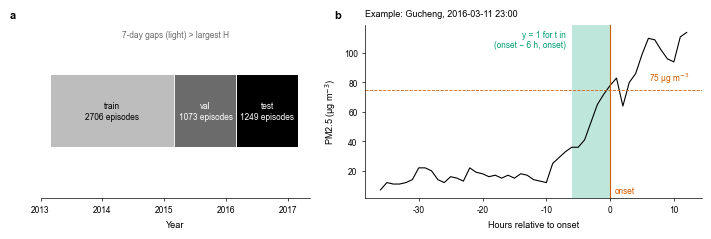

In [28]:
# ---- Fig 5: chia thời gian và một ví dụ nhãn ----
fig = fig_mm(183, 64)
gs = grid_mm(fig, 183, 64, 1, 2, l=12, r=3, t=8, b=12, wsp=14, hsp=0, width_ratios=[1, 1.25])
ax = fig.add_subplot(gs[0]); plab(ax, "a")
yr = lambda t: t.year + (t.dayofyear - 1) / 365.0
fillc = {"train": LGREY, "gap1": "#f0f0f0", "val": GREY, "gap2": "#f0f0f0", "test": OK["black"]}
nep = EP.groupby("split").size().to_dict()
for k, (a, b) in SPLITS.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    ax.barh(0, yr(b) - yr(a) + 1 / 365, left=yr(a), height=0.5, color=fillc[k], lw=0)
    if not k.startswith("gap"):
        ax.text((yr(a) + yr(b)) / 2, 0, f"{k}\n{nep.get(k, 0)} episodes", ha="center", va="center",
                fontsize=FS - 0.5, color="black" if k == "train" else "white")
ax.set_ylim(-0.6, 0.6); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("Year"); ax.set_xticks([2013, 2014, 2015, 2016, 2017])
ax.text(0.5, 0.97, "7-day gaps (light) > largest H", transform=ax.transAxes, ha="center", va="top",
        fontsize=FS - 0.5, color=GREY)

# ví dụ nhãn
axb = fig.add_subplot(gs[1]); plab(axb, "b")
H_EX = 6; ex = None
for _, r in EP[(EP.split == "test")].sort_values("onset_time").iterrows():
    d = panel[r.station]; a = int(r.a)
    w = d[TARGET].iloc[a - 36:a + 13]
    if a > 40 and w.notna().all() and (w.iloc[:36] <= 75).sum() >= 24: ex = (r.station, a); break
if ex is None: ex = (STATIONS[0], int(EP.iloc[0].a))
st, a = ex; d = panel[st]; w = d[TARGET].iloc[a - 36:a + 13]; x = np.arange(-36, 13)
axb.plot(x, w.values, color="black", lw=0.8)
axb.axhline(75, color=OK["verm"], lw=0.6, ls="--"); axb.text(12.5, 78, r"75 µg m$^{-3}$", color=OK["verm"], ha="right", va="bottom", fontsize=FS - 0.5)
axb.axvspan(-H_EX, 0, color=OK["green"], alpha=0.25, lw=0); axb.axvline(0, color=OK["verm"], lw=0.8)
axb.text(-H_EX - 1, axb.get_ylim()[1] * 0.97, f"y = 1 for t in\n(onset − {H_EX} h, onset)", ha="right", va="top", fontsize=FS - 0.5, color=OK["green"])
axb.text(0.8, axb.get_ylim()[1] * 0.04, "onset", color=OK["verm"], fontsize=FS - 0.5)
axb.set_xlabel("Hours relative to onset"); axb.set_ylabel(r"PM2.5 (µg m$^{-3}$)")
axb.set_title(f"Example: {st}, {d.index[a]:%Y-%m-%d %H:%M}", fontsize=FS, loc="left")
save_fig(fig, "fig5_design")
CAPS["Fig. 5"] = (
    f"Fig. 5 | Scenarios and thresholds are chosen on the validation year only; the test year "
    f"({nep.get('test', 0)} episodes) is evaluated once. "
    f"a, chronological split with 7-day gaps (light) longer than the largest H; episodes counted by onset time. "
    f"b, label definition (H = {H_EX} h shown): a clean hour t gets y = 1 if a valid onset occurs within the next H hours. "
    f"The example is the earliest test-year onset whose 36 h before and 12 h after are fully observed and whose "
    f"36 h before include at least 24 h at or below {CFG['THETA']} µg/m³ (chosen by rule). "
    f"Valid onset: PM2.5 > {CFG['THETA']} µg/m³ for ≥ {CFG['N']} h, gaps ≤ {CFG['G']} h bridged. {N_ST} stations.")

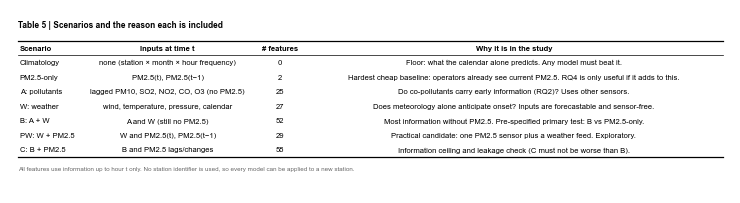

[saved] table5_scenarios (7 rows)


In [29]:
# ---- Table 1: lý do từng kịch bản ----
T1 = pd.DataFrame([
 ("Climatology", "none (station × month × hour frequency)", 0, "Floor: what the calendar alone predicts. Any model must beat it."),
 ("PM2.5-only", "PM2.5(t), PM2.5(t−1)", 2, "Hardest cheap baseline: operators already see current PM2.5. RQ4 is only useful if it adds to this."),
 ("A: pollutants", "lagged PM10, SO2, NO2, CO, O3 (no PM2.5)", len(SCEN["A"]), "Do co-pollutants carry early information (RQ2)? Uses other sensors."),
 ("W: weather", "wind, temperature, pressure, calendar", len(SCEN["W"]), "Does meteorology alone anticipate onset? Inputs are forecastable and sensor-free."),
 ("B: A + W", "A and W (still no PM2.5)", len(SCEN["B"]), "Most information without PM2.5. Pre-specified primary test: B vs PM2.5-only."),
 ("PW: W + PM2.5", "W and PM2.5(t), PM2.5(t−1)", len(SCEN["PW"]), "Practical candidate: one PM2.5 sensor plus a weather feed. Exploratory."),
 ("C: B + PM2.5", "B and PM2.5 lags/changes", len(SCEN["C"]), "Information ceiling and leakage check (C must not be worse than B)."),
], columns=["Scenario", "Inputs at time t", "# features", "Why it is in the study"])
save_table(T1, "table5_scenarios", "Table 5 | Scenarios and the reason each is included",
           "All features use information up to hour t only. No station identifier is used, so every model can be applied to a new station.")

[saved] fig6_scenarios: 183 x 52 mm (limit 183 x 170 mm)


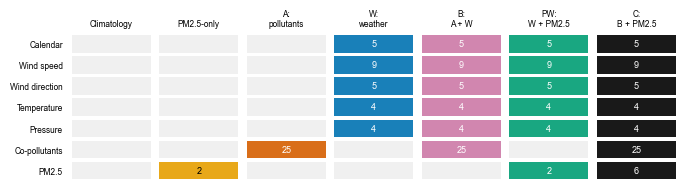

In [30]:
# ---- Fig 2: nhóm đặc trưng × kịch bản ----
rowsg = [("calendar", "Calendar"), ("wind_speed", "Wind speed"), ("wind_dir", "Wind direction"), ("temp", "Temperature"),
         ("pres", "Pressure"), ("pollutant", "Co-pollutants"), ("pm25", "PM2.5")]
colsS = ["climatology", "pm25_only", "GB_A", "GB_W", "GB_B", "GB_PW", "GB_C"]
fig = fig_mm(183, 52); ax = fig.add_axes([0.13, 0.12, 0.85, 0.72])
for j, m in enumerate(colsS):
    cols = set(FEATS.get(m, []))
    for i, (g, gl) in enumerate(rowsg):
        n = len(cols & set(GROUPS[g]))
        ax.add_patch(plt.Rectangle((j - .45, i - .42), .9, .84, color=MC[m] if n else "#f0f0f0", alpha=0.9 if n else 1, lw=0))
        if n: ax.text(j, i, str(n), ha="center", va="center", color="black" if m == "pm25_only" else "white", fontsize=FS)
ax.set_xlim(-.5, len(colsS) - .5); ax.set_ylim(len(rowsg) - .5, -.5)
ax.set_xticks(range(len(colsS))); ax.set_xticklabels([LAB[m].replace(": ", ":\n") for m in colsS]); ax.xaxis.tick_top()
ax.set_yticks(range(len(rowsg))); ax.set_yticklabels([g[1] for g in rowsg])
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
save_fig(fig, "fig6_scenarios")
CAPS["Fig. 6"] = (
    f"Fig. 6 | The six models differ only in which feature groups they see: weather and calendar (W, {len(SCEN['W'])} features), "
    f"co-pollutants (A, {len(SCEN['A'])}) and PM2.5 (PM2.5-only, PW, C); none uses a station identifier. "
    f"Numbers, features per group; blank, group not used. B, A + W; PW, W + PM2.5; C, B + PM2.5; "
    f"climatology uses no features.")

## 5.5. Models and Episode-Level Evaluation Metrics

In [31]:
def fit_climatology(df, m=20):
    st = df.groupby("station")["y"].agg(["sum", "count"]); st_rate = st["sum"] / st["count"]
    cell = df.groupby(["station", "month", "hour"])["y"].agg(["sum", "count"]).reset_index()
    cell["p"] = (cell["sum"] + m * cell["station"].map(st_rate)) / (cell["count"] + m)
    return cell.set_index(["station", "month", "hour"])["p"], st_rate
def predict_climatology(df, cell, st_rate):
    p = cell.reindex(pd.MultiIndex.from_frame(df[["station", "month", "hour"]])).values
    return np.where(np.isnan(p), df["station"].map(st_rate).values, p)
def fit_clim_pool(df, m=20):                       # climatology không biết trạm (dùng cho LOSO)
    base = df["y"].mean(); cell = df.groupby(["month", "hour"])["y"].agg(["sum", "count"])
    return (cell["sum"] + m * base) / (cell["count"] + m), base
def pred_clim_pool(df, p, base):
    v = p.reindex(pd.MultiIndex.from_frame(df[["month", "hour"]])).values
    return np.where(np.isnan(v), base, v)
 
def fit_lgb(cols, params, trn, val):
    cat = [c for c in cols if c == "station_id"]
    dtr = lgb.Dataset(trn[cols], trn["y"], categorical_feature=cat)
    dva = lgb.Dataset(val[cols], val["y"], categorical_feature=cat, reference=dtr)
    p = dict(objective="binary", metric="average_precision", learning_rate=0.05, feature_fraction=0.8,
             bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbosity=-1, seed=SEED, deterministic=True)
    p.update(params)
    return lgb.train(p, dtr, num_boost_round=3000, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False)])
 
GRID = [dict(num_leaves=7, min_child_samples=300), dict(num_leaves=15, min_child_samples=300), dict(num_leaves=31, min_child_samples=300)]
TRAINED = {}
def ensure(H, names):
    """Huấn luyện (nếu chưa có) các mô hình `names` ở tầm báo trước H; chọn siêu tham số theo PR-AUC trên val."""
    if H not in TRAINED:
        Dh = data[data[f"elig_{H}"]].copy(); Dh["y"] = Dh[f"y_{H}"].astype(int)
        tr_, va_, te_ = [Dh[Dh.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]
        cell_, st_ = fit_climatology(tr_)
        TRAINED[H] = dict(tr=tr_, va=va_, te=te_, S_va={"climatology": predict_climatology(va_, cell_, st_)},
                          S_te={"climatology": predict_climatology(te_, cell_, st_)}, MD={}, best={},
                          ctx_va=Ctx(va_, "val", H), ctx_te=Ctx(te_, "test", H))
    T = TRAINED[H]
    for k in names:
        if k in T["MD"] or k == "climatology": continue
        grids = [dict(num_leaves=7, min_child_samples=200)] if k == "pm25_only" else (GRID if H == CFG["H_MAIN"] else GRID[:2])
        best = (-1, None, None)
        for g in grids:
            m = fit_lgb(FEATS[k], g, T["tr"], T["va"]); ap = m.best_score["valid_0"]["average_precision"]
            if ap > best[0]: best = (ap, g, m)
        ap, g, m = best
        T["best"][k] = {**g, "best_iter": m.best_iteration, "val_ap": round(ap, 4)}
        T["MD"][k] = m
        T["S_va"][k] = m.predict(T["va"][FEATS[k]], num_iteration=m.best_iteration)
        T["S_te"][k] = m.predict(T["te"][FEATS[k]], num_iteration=m.best_iteration)
    return T
 
def hour_index(ts): return np.rint(((ts - FULL_START) / pd.Timedelta(hours=1)).values).astype(np.int64)
def emit_alarms(alarm_idx, keys_l, H):
    """Cảnh báo, rồi nghỉ H giờ trong cùng trạm: tối đa 1 cảnh báo mỗi H giờ."""
    out, last = [], -10**9
    for a in alarm_idx:
        k = keys_l[a]
        if k - last >= H: out.append(a); last = k
    return np.array(out, dtype=np.int64)
 
class Ctx:
    """Một tập (val/test) ở tầm báo trước H: nhãn theo giờ + episode cần phát hiện."""
    def __init__(self, df, split, H):
        self.df, self.split, self.H = df, split, H
        self.keys = df["station_id"].values.astype(np.int64) * 100000 + hour_index(df["datetime"])
        assert (np.diff(self.keys) > 0).all()
        self.keys_l, self.y = self.keys.tolist(), df["y"].values.astype(int)
        e = EP[(EP.split == split) & (EP.onset_time >= SPLIT_START[split] + pd.Timedelta(hours=H))]
        kon = e["station"].map(SID).values.astype(np.int64) * 100000 + hour_index(e["onset_time"])
        lo, hi = np.searchsorted(self.keys, kon - H, side="left"), np.searchsorted(self.keys, kon, side="left")
        ok = hi > lo
        self.n_ep, self.kon, self.lo, self.hi = int(ok.sum()), kon[ok], lo[ok], hi[ok]
        self.n_units = df["station"].nunique() * SPLIT_DAYS[split] / 30        # trạm × 30 ngày
        self.t0 = int((SPLIT_START[split] - FULL_START) / pd.Timedelta(hours=1))
        self.n_hours = int(round(SPLIT_DAYS[split] * 24))
        self.st = df["station_id"].values; self.ep_st = (self.kon // 100000).astype(int)
        self.ep_hour = self.kon % 100000 - self.t0; self.row_hour = hour_index(df["datetime"]) - self.t0
        assert self.row_hour.min() >= 0 and self.row_hour.max() < self.n_hours
 
def alarms(c, s, thr):
    """thr: số hoặc mảng theo hàng. Trả về (chỉ số cảnh báo, là cảnh báo giả, episode được phát hiện, lead giờ)."""
    E = emit_alarms(np.flatnonzero(s >= thr).tolist(), c.keys_l, c.H); n = len(c.lo)
    if len(E) == 0: return E, np.zeros(0, bool), np.zeros(n, bool), np.full(n, -1.0)
    pos = np.searchsorted(E, c.lo, side="left"); first = E[np.minimum(pos, len(E) - 1)]
    det = (pos < len(E)) & (first < c.hi)
    return E, c.y[E] == 0, det, np.where(det, c.kon - c.keys[first], -1.0)
 
def summarize(c, s, thr, kmin=1):
    E, fa, det, lead = alarms(c, s, thr); dk = det & (lead >= kmin)
    return dict(n_alarm=len(E), fa_30d=fa.sum() / c.n_units, recall=dk.sum() / c.n_ep,
                lead_med=float(np.median(lead[det])) if det.any() else np.nan)
 
def sweep(c, s, nthr=150):
    """Quét ngưỡng: cảnh báo giả/30 ngày, episode phát hiện với lead >= 1 và >= MIN_LEAD."""
    rows = []
    for thr in np.unique(np.quantile(s, np.linspace(0.30, 0.998, nthr))):
        E, fa, det, lead = alarms(c, s, thr)
        rows.append((thr, fa.sum() / c.n_units, det.sum(), (det & (lead >= DEPLOY["MIN_LEAD"])).sum()))
    return pd.DataFrame(rows, columns=["thr", "fa_30d", "det1", "det3"])
 
def thr_budget(sw, col):
    """Ngưỡng chọn trên VAL: tối đa số episode phát hiện với cảnh báo giả <= ngân sách (hòa -> ngưỡng cao hơn)."""
    ok = (sw.fa_30d <= DEPLOY["BUDGET"]).values
    if not ok.any(): return float(sw.thr.iloc[-1])
    v = sw[col].values; return float(sw.thr.iloc[np.flatnonzero(ok & (v == v[ok].max()))[-1]])
class FastAP:
    """Average precision có trọng số theo hàng (sắp xếp một lần), xử lý điểm bằng nhau như sklearn."""
    def __init__(self, y, s):
        self.o = np.argsort(-s, kind="stable"); ss = s[self.o]; self.y = y[self.o].astype(float)
        self.end = np.r_[np.flatnonzero(np.diff(ss) != 0), len(ss) - 1]
    def __call__(self, w):
        tp, n = np.cumsum(w * self.y), np.cumsum(w); P = tp[-1]
        if P <= 0: return np.nan
        tpe, ne = tp[self.end], n[self.end]
        prec = np.divide(tpe, ne, out=np.zeros_like(tpe), where=ne > 0)
        return float(np.sum(np.diff(tpe / P, prepend=0.0) * prec))
 
def make_W(c, nboot, L=BLOCK_DAYS, seed=2026):
    """Trọng số bootstrap khối L ngày, chung cho mọi mô hình/trạm (hàng 0 = mẫu gốc)."""
    bl = L * 24; nb = int(np.ceil(c.n_hours / bl)); days = np.minimum(bl, c.n_hours - np.arange(nb) * bl) / 24
    rng = np.random.default_rng(seed)
    W = np.vstack([np.ones(nb), np.stack([np.bincount(rng.integers(0, nb, nb), minlength=nb) for _ in range(nboot)])]).astype(float)
    return dict(bl=bl, nb=nb, days=days, W=W)
 
def boot(c, s, thr, BW, kmin=1, ap=True, stations=None):
    """Chỉ số + bootstrap: recall (lead >= kmin), cảnh báo giả/trạm/30 ngày, PR-AUC. stations: danh sách chỉ số trạm hoặc None (gộp)."""
    bl, nb, W = BW["bl"], BW["nb"], BW["W"]
    E, fa, det, lead = alarms(c, s, thr); dk = det & (lead >= kmin)
    sel_e = np.ones(len(c.ep_st), bool) if stations is None else np.isin(c.ep_st, stations)
    a_st = c.keys[E] // 100000
    sel_a = np.ones(len(E), bool) if stations is None else np.isin(a_st, stations)
    nst = N_ST if stations is None else len(stations)
    ep_b = c.ep_hour // bl; a_b = (c.keys[E] % 100000 - c.t0) // bl
    n_ep = W @ np.bincount(ep_b[sel_e], minlength=nb).astype(float)
    dt = W @ np.bincount(ep_b[sel_e], weights=dk[sel_e].astype(float), minlength=nb)
    fa_c = W @ np.bincount(a_b[sel_a], weights=fa[sel_a].astype(float), minlength=nb)
    units = nst * (W @ BW["days"]) / 30
    out = dict(recall=dt / n_ep, fa=fa_c / units, cost=(DEPLOY["R_COST"] * (n_ep - dt) + fa_c) / units)
    if ap:
        mk = np.ones(len(s), bool) if stations is None else np.isin(c.st, stations)
        f = FastAP(c.y[mk], s[mk]); rb = (c.row_hour // bl)[mk][f.o]
        out["pr_auc"] = np.array([f(W[i][rb]) for i in range(len(W))])
    return out
print("Công cụ sẵn sàng.")

Công cụ sẵn sàng.


# 6. RQ4 – Results at H = 6 Hours (Single-Pass Test Evaluation)
## 6.1 Two Threshold-Selection Strategies, Both Tuned on Validation:
## Budget-based ( 12 false alarms per station per 30 days, maximizing the number of detected episodes for fair model comparison) and Cost-based (missed detections : false alarms = 10 : 1).

H=6: mẫu train 111284 / val 62811 / test 59545; tỷ lệ dương test 0.121; episode đánh giá: val 1073, test 1249
{'pm25_only': {'num_leaves': 7, 'min_child_samples': 200, 'best_iter': 298, 'val_ap': np.float64(0.3831)}, 'GB_A': {'num_leaves': 7, 'min_child_samples': 300, 'best_iter': 341, 'val_ap': np.float64(0.2834)}, 'GB_W': {'num_leaves': 31, 'min_child_samples': 300, 'best_iter': 340, 'val_ap': np.float64(0.3115)}, 'GB_B': {'num_leaves': 15, 'min_child_samples': 300, 'best_iter': 302, 'val_ap': np.float64(0.3833)}, 'GB_PW': {'num_leaves': 15, 'min_child_samples': 300, 'best_iter': 264, 'val_ap': np.float64(0.4494)}, 'GB_C': {'num_leaves': 31, 'min_child_samples': 300, 'best_iter': 239, 'val_ap': np.float64(0.4553)}}
Tỷ lệ dương test (PR-AUC ngẫu nhiên) = 0.121


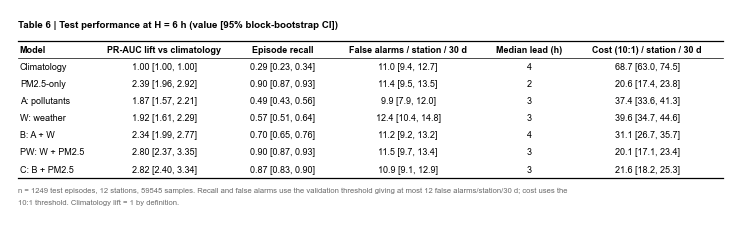

[saved] table6_rq4_H6 (7 rows)


In [32]:
Hm = CFG["H_MAIN"]
T6 = ensure(Hm, ["pm25_only", "GB_A", "GB_W", "GB_B", "GB_PW", "GB_C"])
cv, ct = T6["ctx_va"], T6["ctx_te"]
print(f"H={Hm}: mẫu train {len(T6['tr'])} / val {len(T6['va'])} / test {len(T6['te'])}; tỷ lệ dương test {ct.y.mean():.3f}; "
      f"episode đánh giá: val {cv.n_ep}, test {ct.n_ep}")
print({k: T6["best"][k] for k in T6["best"]})
SW6 = {m: sweep(cv, T6["S_va"][m]) for m in MODEL_ORDER}
def thr_cost(sw, n_ep, r=DEPLOY["R_COST"]):
    cost = r * (n_ep - sw.det1.values) + sw.fa_30d.values * cv.n_units        # cảnh báo giả đếm tuyệt đối
    return float(sw.thr.iloc[np.flatnonzero(cost == cost.min())[-1]])
THR6 = {"bud": {m: thr_budget(SW6[m], "det1") for m in MODEL_ORDER},
        "cost": {m: thr_cost(SW6[m], cv.n_ep) for m in MODEL_ORDER}}
BW6 = make_W(ct, NBOOT)
B6 = {(sc, m): boot(ct, T6["S_te"][m], THR6[sc][m], BW6) for sc in ["bud", "cost"] for m in MODEL_ORDER}
LEAD6 = {m: summarize(ct, T6["S_te"][m], THR6["bud"][m])["lead_med"] for m in MODEL_ORDER}
clim_ap = B6[("bud", "climatology")]["pr_auc"]
rows = []
for m in MODEL_ORDER:
    b, c_ = B6[("bud", m)], B6[("cost", m)]
    rows.append({"Model": LAB[m], "PR-AUC lift vs climatology": ci_str(b["pr_auc"] / clim_ap),
                 "Episode recall": ci_str(b["recall"]), "False alarms / station / 30 d": ci_str(b["fa"], 1),
                 "Median lead (h)": f"{LEAD6[m]:.0f}" if not np.isnan(LEAD6[m]) else "–",
                 "Cost (10:1) / station / 30 d": ci_str(c_["cost"], 1)})
T2 = pd.DataFrame(rows)
print(f"Tỷ lệ dương test (PR-AUC ngẫu nhiên) = {ct.y.mean():.3f}")
save_table(T2, "table6_rq4_H6", f"Table 6 | Test performance at H = {Hm} h (value [95% block-bootstrap CI])",
           f"n = {ct.n_ep} test episodes, 12 stations, {len(T6['te'])} samples. Recall and false alarms use the validation threshold giving at most "
           f"{DEPLOY['BUDGET']} false alarms/station/30 d; cost uses the 10:1 threshold. Climatology lift = 1 by definition.")

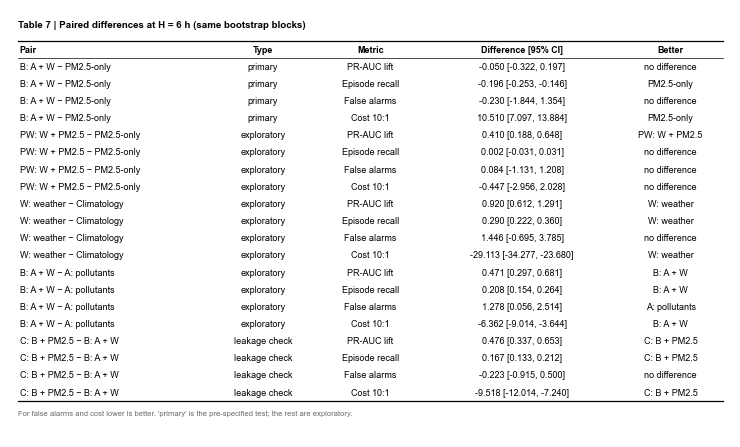

[saved] table7_pairs_H6 (20 rows)
TIÊU CHÍ ĐẶT TRƯỚC (B vượt PM2.5-only về PR-AUC VÀ recall cùng ngân sách): KHÔNG ĐẠT


In [33]:
# ---- So sánh cặp (pre-specified: B vs PM2.5-only; còn lại khám phá) ----
PAIRS = [("GB_B", "pm25_only", "primary"), ("GB_PW", "pm25_only", "exploratory"), ("GB_W", "climatology", "exploratory"),
         ("GB_B", "GB_A", "exploratory"), ("GB_C", "GB_B", "leakage check")]
HIGHER = {"pr_auc": True, "recall": True, "fa": False, "cost": False}
def pair_rows(Bd, pairs, mets, tag=""):
    rows = []
    for a, b, note in pairs:
        for met in mets:
            sc = "cost" if met == "cost" else "bud"
            d = (Bd[(sc, a)][met] / (Bd[(sc, "climatology")]["pr_auc"] if met == "pr_auc" else 1)) - \
                (Bd[(sc, b)][met] / (Bd[(sc, "climatology")]["pr_auc"] if met == "pr_auc" else 1))
            lo, hi = ci(d); v = "no difference" if lo <= 0 <= hi else (LAB[a] if (d[0] > 0) == HIGHER[met] else LAB[b])
            rows.append({"Pair": f"{LAB[a]} − {LAB[b]}", "Type": note, "Metric": {"pr_auc": "PR-AUC lift", "recall": "Episode recall",
                         "fa": "False alarms", "cost": "Cost 10:1"}[met], "Difference [95% CI]": ci_str(d, 3), "Better": v})
    return pd.DataFrame(rows)
T3 = pair_rows(B6, PAIRS, ["pr_auc", "recall", "fa", "cost"])
save_table(T3, "table7_pairs_H6", f"Table 7 | Paired differences at H = {Hm} h (same bootstrap blocks)",
           "For false alarms and cost lower is better. 'primary' is the pre-specified test; the rest are exploratory.")
p = T3[(T3.Pair == "B: A + W − PM2.5-only")].set_index("Metric")
okp = (ci(B6[("bud", "GB_B")]["pr_auc"] / clim_ap - B6[("bud", "pm25_only")]["pr_auc"] / clim_ap)[0] > 0) and \
      (ci(B6[("bud", "GB_B")]["recall"] - B6[("bud", "pm25_only")]["recall"])[0] > 0)
print("TIÊU CHÍ ĐẶT TRƯỚC (B vượt PM2.5-only về PR-AUC VÀ recall cùng ngân sách):", "ĐẠT" if okp else "KHÔNG ĐẠT")

[saved] fig7_rq4_H6: 183 x 66 mm (limit 183 x 170 mm)


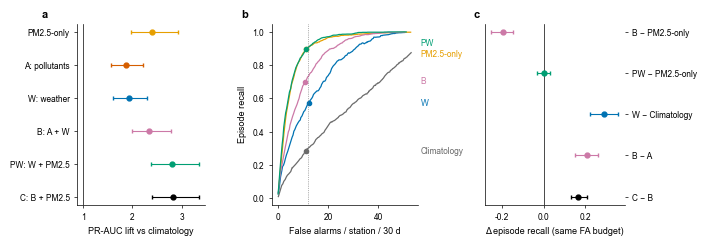

In [34]:
# ---- Fig 3 ----
fig = fig_mm(183, 66)
gs = grid_mm(fig, 183, 66, 1, 3, l=22, r=22, t=7, b=13, wsp=17, hsp=0, width_ratios=[1, 1.15, 1.1])
ax = fig.add_subplot(gs[0]); plab(ax, "a", dx=-26)
ms = MODEL_ORDER[1:]
for i, m in enumerate(ms):
    v = B6[("bud", m)]["pr_auc"] / clim_ap; lo, hi = ci(v)
    ax.errorbar(v[0], i, xerr=[[v[0] - lo], [hi - v[0]]], fmt="o", color=MC[m], ms=3.5, lw=0.8, capsize=1.5)
ax.axvline(1, color="black", lw=0.5); ax.set_yticks(range(len(ms))); ax.set_yticklabels([LAB[m] for m in ms]); ax.invert_yaxis()
ax.set_xlabel("PR-AUC lift vs climatology")
ax = fig.add_subplot(gs[1]); plab(ax, "b", dx=-22)
for m in ["climatology", "pm25_only", "GB_W", "GB_B", "GB_PW"]:
    sw = sweep(ct, T6["S_te"][m]); ax.plot(sw.fa_30d, sw.det1 / ct.n_ep, color=MC[m], lw=0.9)
    j = np.argmin(np.abs(sw.thr - THR6["bud"][m])); ax.plot(sw.fa_30d[j], sw.det1[j] / ct.n_ep, "o", color=MC[m], ms=3)
ax.axvline(DEPLOY["BUDGET"], color=GREY, lw=0.5, ls=":")
mb = ["climatology", "pm25_only", "GB_W", "GB_B", "GB_PW"]
end_labels(ax, ax.get_xlim()[1], [B6[("bud", m)]["recall"][0] for m in mb], [LAB[m].split(":")[0] for m in mb], [MC[m] for m in mb], 0.07, pad=ax.get_xlim()[1] * 0.02)
ax.set_xlabel("False alarms / station / 30 d"); ax.set_ylabel("Episode recall")
ax = fig.add_subplot(gs[2]); plab(ax, "c", dx=-8)
for i, (a, b, note) in enumerate(PAIRS):
    d = B6[("bud", a)]["recall"] - B6[("bud", b)]["recall"]; lo, hi = ci(d)
    ax.errorbar(d[0], i, xerr=[[d[0] - lo], [hi - d[0]]], fmt="o", color=MC[a], ms=3.5, lw=0.8, capsize=1.5)
ax.axvline(0, color="black", lw=0.5); ax.set_yticks(range(len(PAIRS)))
ax.set_yticklabels([f"{LAB[a].split(':')[0]} − {LAB[b].split(':')[0]}" for a, b, _ in PAIRS]); ax.invert_yaxis()
ax.yaxis.tick_right(); ax.set_xlabel("Δ episode recall (same FA budget)")
save_fig(fig, "fig7_rq4_H6")
rec7 = lambda m: B6[("bud", m)]["recall"][0]
dpw = B6[("bud", "GB_PW")]["recall"] - B6[("bud", "pm25_only")]["recall"]; lo7, hi7 = ci(dpw)
verb7 = "matched" if lo7 <= 0 <= hi7 else ("exceeded" if lo7 > 0 else "fell below")
CAPS["Fig. 7"] = (
    f"Fig. 7 | At H = {Hm} h, weather plus co-pollutants (B) {'met' if okp else 'did not meet'} the pre-specified criterion of "
    f"beating PM2.5-only on PR-AUC lift and recall (recall {rec7('GB_B'):.2f} vs {rec7('pm25_only'):.2f}), "
    f"whereas weather plus PM2.5 (PW) {verb7} it ({rec7('GB_PW'):.2f}). "
    f"a, PR-AUC lift over climatology (PR-AUC divided by climatology PR-AUC). "
    f"b, episode recall against false alarms (FA) per station per 30 d on the test year (dots, validation-chosen threshold; "
    f"dotted line, {DEPLOY['BUDGET']}/30 d budget). c, paired recall differences at equal FA budget. "
    f"Error bars: 95% CI, {BLOCK_DAYS}-day block bootstrap ({NBOOT} resamples). "
    f"n = {ct.n_ep} test episodes, {N_ST} stations. A, co-pollutants; W, weather; B, A + W; PW, W + PM2.5; C, B + PM2.5.")

## 7. RQ4 – How Far in Advance Can Episodes Be Predicted? (H = 1, 3, 6, 12, 24 Hours)

H= 1: xong (16s) | dương 0.020 | episode test 1249
H= 3: xong (33s) | dương 0.062 | episode test 1249
H= 6: xong (37s) | dương 0.121 | episode test 1249
H=12: xong (55s) | dương 0.218 | episode test 1246
H=24: xong (67s) | dương 0.369 | episode test 1220


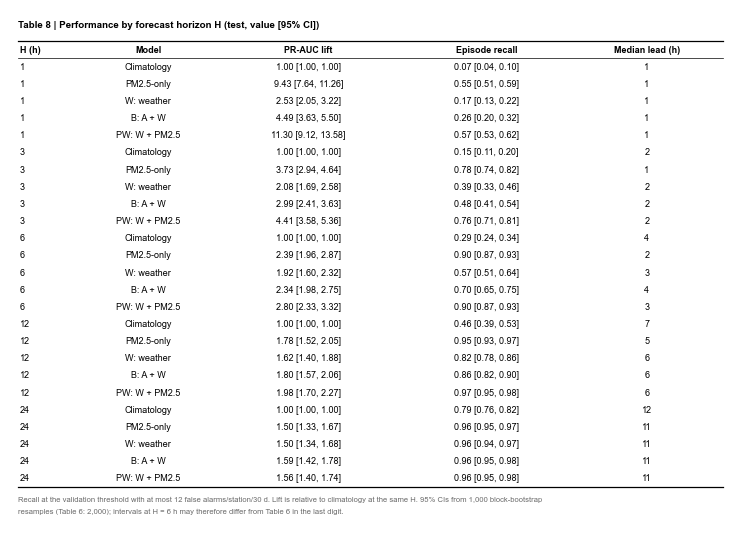

[saved] table8_horizon (25 rows)
  H= 1: 0.021 [-0.016, 0.056]
  H= 3: -0.017 [-0.053, 0.019]
  H= 6: 0.002 [-0.028, 0.033]
  H=12: 0.012 [0.000, 0.027]
  H=24: 0.003 [-0.004, 0.011]
W − climatology (lift PR-AUC) theo H:
  H= 1: 2.53 [2.05, 3.22]
  H= 3: 2.08 [1.69, 2.58]
  H= 6: 1.92 [1.60, 2.32]
  H=12: 1.62 [1.40, 1.88]
  H=24: 1.50 [1.34, 1.68]


In [35]:
SWEEP_MODELS = ["pm25_only", "GB_W", "GB_B", "GB_PW"]
RESH, t0_ = {}, time.time()
for H in CFG["H_LIST"]:
    T = ensure(H, SWEEP_MODELS); cvH, ctH = T["ctx_va"], T["ctx_te"]
    BWH = make_W(ctH, max(NBOOT // 2, 40), seed=7)
    r = {}
    for m in ["climatology"] + SWEEP_MODELS:
        thr = thr_budget(sweep(cvH, T["S_va"][m]), "det1")
        r[m] = dict(b=boot(ctH, T["S_te"][m], thr, BWH), lead=summarize(ctH, T["S_te"][m], thr)["lead_med"])
    RESH[H] = dict(r=r, pos=ctH.y.mean(), n_ep=ctH.n_ep)
    print(f"H={H:>2}: xong ({time.time() - t0_:.0f}s) | dương {ctH.y.mean():.3f} | episode test {ctH.n_ep}")
rows = []
for H in CFG["H_LIST"]:
    r = RESH[H]["r"]; clim = r["climatology"]["b"]["pr_auc"]
    for m in ["climatology"] + SWEEP_MODELS:
        rows.append({"H (h)": H, "Model": LAB[m], "PR-AUC lift": ci_str(r[m]["b"]["pr_auc"] / clim),
                     "Episode recall": ci_str(r[m]["b"]["recall"]), "Median lead (h)": f"{r[m]['lead']:.0f}" if not np.isnan(r[m]["lead"]) else "–"})
T4 = pd.DataFrame(rows)
save_table(T4, "table8_horizon", "Table 8 | Performance by forecast horizon H (test, value [95% CI])",
           f"Recall at the validation threshold with at most {DEPLOY['BUDGET']} false alarms/station/30 d. "
           f"Lift is relative to climatology at the same H. "
           f"95% CIs from {max(NBOOT // 2, 40):,} block-bootstrap resamples (Table 6: {NBOOT:,}); "
           f"intervals at H = 6 h may therefore differ from Table 6 in the last digit.")
for H in CFG["H_LIST"]:
    d = RESH[H]["r"]["GB_PW"]["b"]["recall"] - RESH[H]["r"]["pm25_only"]["b"]["recall"]; print(f"  H={H:>2}: {ci_str(d, 3)}")
print("W − climatology (lift PR-AUC) theo H:")
for H in CFG["H_LIST"]:
    d = RESH[H]["r"]["GB_W"]["b"]["pr_auc"] / RESH[H]["r"]["climatology"]["b"]["pr_auc"]; print(f"  H={H:>2}: {ci_str(d, 2)}")

[saved] fig8_horizon: 183 x 58 mm (limit 183 x 170 mm)


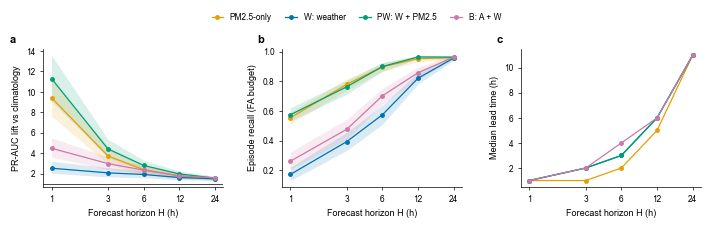

In [36]:
from matplotlib.lines import Line2D
fig = fig_mm(183, 58)
gs = grid_mm(fig, 183, 58, 1, 3, l=12, r=4, t=11, b=12, wsp=15, hsp=0)
mm_ = ["pm25_only", "GB_W", "GB_PW", "GB_B"]; Hs = CFG["H_LIST"]
clim8 = {H: RESH[H]["r"]["climatology"]["b"]["pr_auc"] for H in Hs}
for k, (key_, yl) in enumerate([("lift", "PR-AUC lift vs climatology"),
                                ("recall", "Episode recall (FA budget)"),
                                ("lead", "Median lead time (h)")]):
    ax = fig.add_subplot(gs[k]); plab(ax, "abc"[k], dx=-24 if k == 0 else -18)
    for m in mm_:
        if key_ == "lift":
            v = [RESH[H]["r"][m]["b"]["pr_auc"] / clim8[H] for H in Hs]
            ax.fill_between(Hs, [ci(x)[0] for x in v], [ci(x)[1] for x in v], color=MC[m], alpha=0.15, lw=0)
            y = [x[0] for x in v]
        elif key_ == "recall":
            v = [RESH[H]["r"][m]["b"]["recall"] for H in Hs]
            ax.fill_between(Hs, [ci(x)[0] for x in v], [ci(x)[1] for x in v], color=MC[m], alpha=0.15, lw=0)
            y = [x[0] for x in v]
        else:
            y = [RESH[H]["r"][m]["lead"] for H in Hs]
        ax.plot(Hs, y, "-o", color=MC[m], ms=2.5)
    if key_ == "lift": ax.axhline(1, color="black", lw=0.5)
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(Hs); ax.set_xticklabels(Hs)
    ax.set_xlabel("Forecast horizon H (h)"); ax.set_ylabel(yl)
# one shared legend above the panels (never over data)
fig.legend([Line2D([0], [0], color=MC[m], marker="o", ms=2.5, lw=0.9) for m in mm_], [LAB[m] for m in mm_],
           ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=FS - 0.5,
           handlelength=1.4, columnspacing=1.6)
save_fig(fig, "fig8_horizon")

lift8 = lambda m, H: RESH[H]["r"][m]["b"]["pr_auc"][0] / clim8[H][0]
rec8 = lambda m, H: RESH[H]["r"][m]["b"]["recall"][0]
dmax = max(abs(rec8("GB_PW", H) - rec8("pm25_only", H)) for H in Hs)
n_lo, n_hi = min(RESH[H]["n_ep"] for H in Hs), max(RESH[H]["n_ep"] for H in Hs)
CAPS["Fig. 8"] = (
    f"Fig. 8 | Lift over climatology shrinks as H grows (PM2.5-only {lift8('pm25_only', Hs[0]):.1f}× at H = {Hs[0]} h to "
    f"{lift8('pm25_only', Hs[-1]):.1f}× at {Hs[-1]} h) while episode recall rises ({rec8('pm25_only', Hs[0]):.2f} to "
    f"{rec8('pm25_only', Hs[-1]):.2f}); adding weather to PM2.5 (PW) changes recall by at most {dmax:.2f} at any H. "
    f"a, PR-AUC lift over climatology at the same H. b, episode recall at the validation threshold allowing ≤ {DEPLOY['BUDGET']} "
    f"false alarms (FA) per station per 30 d. c, median lead time of detected episodes. "
    f"Bands: 95% CI, {BLOCK_DAYS}-day block bootstrap ({max(NBOOT // 2, 40)} resamples). "
    f"Test year, {N_ST} stations, n = {n_lo:,}–{n_hi:,} episodes depending on H. "
    f"PM2.5, PM2.5-only baseline; W, weather; B, weather + co-pollutants; PW, weather + PM2.5.")

# 8. Selecting a Model for Practical Deployment

Ứng viên tốt nhất theo recall dùng được (val): ['GB_C', np.int64(12)] = 0.779
=> CHỌN: PW: W + PM2.5 ở H = 12 h (recall dùng được val 0.775, cảnh báo giả val 12.0/trạm/30 ngày)


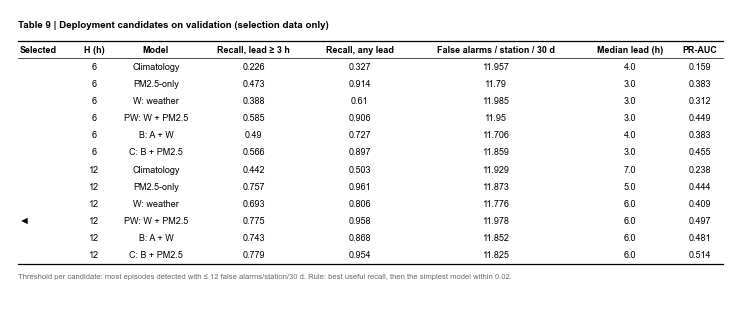

[saved] table9_deploy_candidates (12 rows)


In [37]:
DEP_MODELS = ["pm25_only", "GB_W", "GB_PW", "GB_B", "GB_C"]
COMPLEX = {"pm25_only": 0, "GB_W": 1, "GB_PW": 2, "GB_B": 3, "GB_C": 4}      # số nguồn dữ liệu cần lúc vận hành
CAND = []
for H in DEPLOY["H_CAND"]:
    T = ensure(H, DEP_MODELS); cvH = T["ctx_va"]
    for m in ["climatology"] + DEP_MODELS:
        sw = sweep(cvH, T["S_va"][m]); thr = thr_budget(sw, "det3")
        s = summarize(cvH, T["S_va"][m], thr, kmin=DEPLOY["MIN_LEAD"]); s1 = summarize(cvH, T["S_va"][m], thr, kmin=1)
        CAND.append(dict(H=H, model=m, thr=thr, val_fa=s["fa_30d"], val_recall_useful=s["recall"], val_recall_any=s1["recall"],
                         val_lead=s["lead_med"], val_ap=average_precision_score(cvH.y, T["S_va"][m]), n_ep=cvH.n_ep))
CD = pd.DataFrame(CAND)
cands = CD[CD.model != "climatology"]
best_r = cands.val_recall_useful.max()
near = cands[cands.val_recall_useful >= best_r - DEPLOY["EPS"]].copy()
near["rank"] = near.model.map(COMPLEX); near = near.sort_values(["rank", "H"])
SEL = near.iloc[0]; DEP_H, DEP_M = int(SEL.H), SEL.model
print(f"Ứng viên tốt nhất theo recall dùng được (val): {cands.loc[cands.val_recall_useful.idxmax(), ['model', 'H']].tolist()} = {best_r:.3f}")
print(f"=> CHỌN: {LAB[DEP_M]} ở H = {DEP_H} h (recall dùng được val {SEL.val_recall_useful:.3f}, cảnh báo giả val {SEL.val_fa:.1f}/trạm/30 ngày)")
T8 = CD.assign(Model=CD.model.map(LAB))[["H", "Model", "val_recall_useful", "val_recall_any", "val_fa", "val_lead", "val_ap"]].round(3)
T8.columns = ["H (h)", "Model", f"Recall, lead ≥ {DEPLOY['MIN_LEAD']} h", "Recall, any lead", "False alarms / station / 30 d", "Median lead (h)", "PR-AUC"]
T8.insert(0, "Selected", ["◄" if (r.H == DEP_H and r.model == DEP_M) else "" for r in CD.itertuples()])
save_table(T8, "table9_deploy_candidates", "Table 9 | Deployment candidates on validation (selection data only)",
           f"Threshold per candidate: most episodes detected with ≤ {DEPLOY['BUDGET']} false alarms/station/30 d. Rule: best useful recall, then the simplest model within {DEPLOY['EPS']:.2f}.")

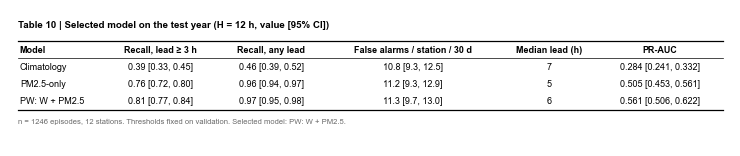

[saved] table10_deploy_test (3 rows)


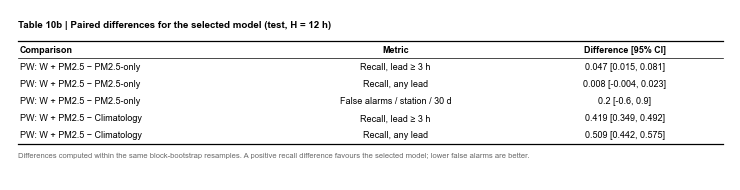

[saved] table10b_deploy_diff (5 rows)
ĐẠT  G1 recall(lead>=3h) vượt climatology (KTC dưới của hiệu số > 0)
ĐẠT  G2 cảnh báo giả test <= 1.25 × ngân sách (15)
ĐẠT  G3 lead trung vị >= 3 h
Hiệu số so với persistence (PM2.5-only), recall lead>=3h: 0.047 [0.015, 0.081]  -> hơn
KẾT LUẬN: mô hình SẴN SÀNG triển khai (cả 3 cổng đạt)


In [38]:
# ---- Kiểm chứng trên TEST (chạm một lần): mô hình chọn so với persistence và climatology cùng H ----
TD = TRAINED[DEP_H]; cD = TD["ctx_te"]; BWD = make_W(cD, NBOOT, seed=99)
thrD = {m: float(CD[(CD.H == DEP_H) & (CD.model == m)].thr.iloc[0]) for m in ["climatology"] + DEP_MODELS}
KD = DEPLOY["MIN_LEAD"]
BD = {m: boot(cD, TD["S_te"][m], thrD[m], BWD, kmin=KD) for m in ["climatology", "pm25_only", DEP_M]}
BD1 = {m: boot(cD, TD["S_te"][m], thrD[m], BWD, kmin=1, ap=False) for m in ["climatology", "pm25_only", DEP_M]}
LEADD = {m: summarize(cD, TD["S_te"][m], thrD[m], KD)["lead_med"] for m in BD}
rows = []
for m in dict.fromkeys(["climatology", "pm25_only", DEP_M]):
    rows.append({"Model": LAB[m], f"Recall, lead ≥ {KD} h": ci_str(BD[m]["recall"]), "Recall, any lead": ci_str(BD1[m]["recall"]),
                 "False alarms / station / 30 d": ci_str(BD[m]["fa"], 1), "Median lead (h)": f"{LEADD[m]:.0f}",
                 "PR-AUC": ci_str(BD[m]["pr_auc"], 3)})
T6_ = pd.DataFrame(rows)
save_table(T6_, "table10_deploy_test", f"Table 10 | Selected model on the test year (H = {DEP_H} h, value [95% CI])",
           f"n = {cD.n_ep} episodes, 12 stations. Thresholds fixed on validation. Selected model: {LAB[DEP_M]}.")
d_clim = BD[DEP_M]["recall"] - BD["climatology"]["recall"]
d_pers = BD[DEP_M]["recall"] - BD["pm25_only"]["recall"]; fa_d = BD[DEP_M]["fa"]
# ---- NEW: headline differences as a table ----
d_pers1 = BD1[DEP_M]["recall"] - BD1["pm25_only"]["recall"]          # any lead
d_clim1 = BD1[DEP_M]["recall"] - BD1["climatology"]["recall"]
d_fa = BD[DEP_M]["fa"] - BD["pm25_only"]["fa"]
T6b = pd.DataFrame([
    {"Comparison": f"{LAB[DEP_M]} − PM2.5-only",  "Metric": f"Recall, lead ≥ {KD} h",       "Difference [95% CI]": ci_str(d_pers, 3)},
    {"Comparison": f"{LAB[DEP_M]} − PM2.5-only",  "Metric": "Recall, any lead",              "Difference [95% CI]": ci_str(d_pers1, 3)},
    {"Comparison": f"{LAB[DEP_M]} − PM2.5-only",  "Metric": "False alarms / station / 30 d", "Difference [95% CI]": ci_str(d_fa, 1)},
    {"Comparison": f"{LAB[DEP_M]} − Climatology", "Metric": f"Recall, lead ≥ {KD} h",       "Difference [95% CI]": ci_str(d_clim, 3)},
    {"Comparison": f"{LAB[DEP_M]} − Climatology", "Metric": "Recall, any lead",              "Difference [95% CI]": ci_str(d_clim1, 3)}])
save_table(T6b, "table10b_deploy_diff", f"Table 10b | Paired differences for the selected model (test, H = {DEP_H} h)",
           "Differences computed within the same block-bootstrap resamples. A positive recall difference favours the selected model; lower false alarms are better.")
GATE = {f"G1 recall(lead>={KD}h) vượt climatology (KTC dưới của hiệu số > 0)": ci(d_clim)[0] > 0,
        f"G2 cảnh báo giả test <= 1.25 × ngân sách ({1.25 * DEPLOY['BUDGET']:.0f})": fa_d[0] <= 1.25 * DEPLOY["BUDGET"],
        f"G3 lead trung vị >= {KD} h": LEADD[DEP_M] >= KD}
for k, v in GATE.items(): print(("ĐẠT  " if v else "KHÔNG ") + k)
print(f"Hiệu số so với persistence (PM2.5-only), recall lead>={KD}h: {ci_str(d_pers, 3)}  -> "
      + ("mô hình chọn chính là persistence" if DEP_M == "pm25_only" else ("hơn" if ci(d_pers)[0] > 0 else "không hơn có ý nghĩa")))
print("KẾT LUẬN: mô hình", "SẴN SÀNG triển khai (cả 3 cổng đạt)" if all(GATE.values()) else "CHƯA đạt đủ cổng — xem cổng không đạt")

[saved] fig9_deployment: 183 x 104 mm (limit 183 x 170 mm)


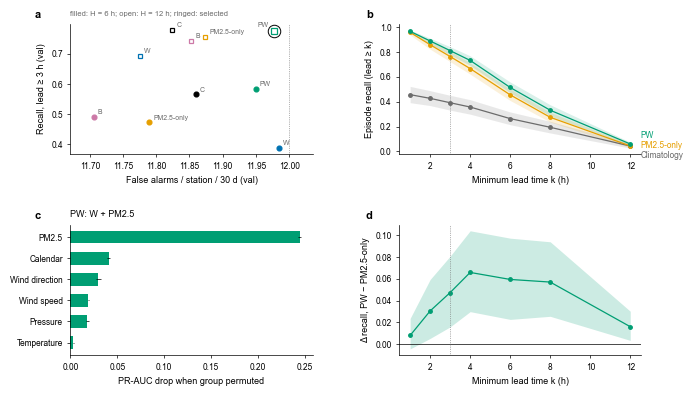

In [39]:
# ---- Fig 9: ứng viên (val), recall theo lead tối thiểu (test), nhóm đặc trưng quan trọng, hiệu số so với PM2.5-only ----
def perm_importance(T, name, n_rep=5, seed=0):
    mdl, cols = T["MD"][name], FEATS[name]; X, y = T["te"][cols].copy(), T["te"].y.values
    pred = lambda Z: mdl.predict(Z, num_iteration=mdl.best_iteration); base = average_precision_score(y, pred(X))
    rng = np.random.default_rng(seed); st_idx = [np.flatnonzero(T["te"].station.values == s) for s in STATIONS]
    rows = []
    for g, gc in GROUPS.items():
        gc = [c for c in gc if c in cols]
        if not gc: continue
        pc, drops = [X.columns.get_loc(c) for c in gc], []
        for _ in range(n_rep):
            Xp = X.copy()
            for idx in st_idx: Xp.iloc[idx, pc] = X.iloc[rng.permutation(idx), pc].values
            drops.append(base - average_precision_score(y, pred(Xp)))
        rows.append((g, np.mean(drops), np.std(drops)))
    return pd.DataFrame(rows, columns=["group", "drop", "sd"]).sort_values("drop")

IMPD = perm_importance(TD, DEP_M, 3 if QUICK else 8)
NAMES9 = {"pm25": "PM2.5", "calendar": "Calendar", "wind_dir": "Wind direction", "wind_speed": "Wind speed",
          "pres": "Pressure", "temp": "Temperature", "pollutant": "Co-pollutants", "dewp": "Dew point", "rain": "Rain"}

ks = [k for k in [1, 2, 3, 4, 6, 8, 12] if k <= DEP_H]
BWk = make_W(cD, max(NBOOT // 2, 40), seed=5)
MK = list(dict.fromkeys(["climatology", "pm25_only", DEP_M]))
RK = {m: [boot(cD, TD["S_te"][m], thrD[m], BWk, kmin=k, ap=False)["recall"] for k in ks] for m in MK}   # same blocks -> paired
SHORT9 = lambda m: LAB[m].split(":")[0]

fig = fig_mm(183, 104)
gs = grid_mm(fig, 183, 104, 2, 2, l=16, r=22, t=8, b=12, wsp=22, hsp=18)

# a: validation candidates
ax = fig.add_subplot(gs[0, 0]); plab(ax, "a", dx=-26)
for r in CD[CD.model != "climatology"].itertuples():
    sel = (r.H == DEP_H and r.model == DEP_M)
    ax.plot(r.val_fa, r.val_recall_useful, "o" if r.H == 6 else "s", ms=5 if sel else 3.5, color=MC[r.model],
            mfc=MC[r.model] if r.H == 6 else "white", mew=0.9, zorder=3)
    ax.annotate(SHORT9(r.model), (r.val_fa, r.val_recall_useful), xytext=(-4 if sel else 3, 3 if sel else 2),
                textcoords="offset points", ha="right" if sel else "left", fontsize=FS - 1.5, color=GREY)
    if sel: ax.plot(r.val_fa, r.val_recall_useful, "o", ms=9, mfc="none", mec="black", mew=0.7, zorder=4)
ax.axvline(DEPLOY["BUDGET"], color=GREY, lw=0.5, ls=":"); ax.margins(x=0.12)
ax.set_title("filled: H = 6 h; open: H = 12 h; ringed: selected", fontsize=FS - 1, loc="left", color=GREY)
ax.set_xlabel("False alarms / station / 30 d (val)"); ax.set_ylabel(f"Recall, lead ≥ {KD} h (val)")

# b: recall vs minimum lead (test)
ax = fig.add_subplot(gs[0, 1]); plab(ax, "b", dx=-24)
for m in MK:
    v = RK[m]
    ax.fill_between(ks, [ci(x)[0] for x in v], [ci(x)[1] for x in v], color=MC[m], alpha=0.15, lw=0)
    ax.plot(ks, [x[0] for x in v], "-o", color=MC[m], ms=2.5)
end_labels(ax, ks[-1], [RK[m][-1][0] for m in MK], [SHORT9(m) for m in MK], [MC[m] for m in MK], min_sep=0.08, pad=0.5)
ax.axvline(KD, color=GREY, lw=0.5, ls=":")
ax.set_xlabel("Minimum lead time k (h)"); ax.set_ylabel("Episode recall (lead ≥ k)")

# c: permutation importance (readable group names)
ax = fig.add_subplot(gs[1, 0]); plab(ax, "c", dx=-26)
ax.barh([NAMES9.get(g, g) for g in IMPD.group], IMPD["drop"], xerr=IMPD["sd"], color=MC[DEP_M], height=0.6, error_kw=dict(lw=0.5))
ax.set_xlabel("PR-AUC drop when group permuted"); ax.set_title(LAB[DEP_M], fontsize=FS, loc="left")

# d: paired difference vs PM2.5-only (the headline claim)
ax = fig.add_subplot(gs[1, 1]); plab(ax, "d", dx=-24)
d9 = [RK[DEP_M][i] - RK["pm25_only"][i] for i in range(len(ks))]
ax.fill_between(ks, [ci(x)[0] for x in d9], [ci(x)[1] for x in d9], color=MC[DEP_M], alpha=0.2, lw=0)
ax.plot(ks, [x[0] for x in d9], "-o", color=MC[DEP_M], ms=2.5)
ax.axhline(0, color="black", lw=0.5); ax.axvline(KD, color=GREY, lw=0.5, ls=":")
ax.set_xlabel("Minimum lead time k (h)"); ax.set_ylabel(f"Δ recall, {SHORT9(DEP_M)} − PM2.5-only")
save_fig(fig, "fig9_deployment")

top9 = NAMES9.get(IMPD.iloc[-1]["group"], IMPD.iloc[-1]["group"])
d9k = d9[ks.index(KD)]; lo9, hi9 = ci(d9k)
verb9 = "improves on" if lo9 > 0 else "does not clearly differ from"
CAPS["Fig. 9"] = (
    f"Fig. 9 | At H = {DEP_H} h the selected model ({LAB[DEP_M]}) {verb9} the PM2.5-only baseline in recall when a warning must "
    f"lead the onset by ≥ {KD} h ({d9k[0]:+.3f} [{lo9:+.3f}, {hi9:+.3f}]); {top9} is its most important feature group. "
    f"a, validation candidates (scenario × H) at the {DEPLOY['BUDGET']}-false-alarm budget; thresholds use the full budget, so the "
    f"x-axis spans a narrow range; the rule picks the best useful recall, then the simplest model within {DEPLOY['EPS']:.2f}. "
    f"b, test recall when a warning must lead by at least k hours (same thresholds). "
    f"c, permutation importance by feature group on the test year (mean ± SD of {3 if QUICK else 8} within-station shuffles). "
    f"d, paired recall difference, selected model minus PM2.5-only, by minimum lead k. "
    f"Bands: 95% CI, {BLOCK_DAYS}-day block bootstrap ({max(NBOOT // 2, 40)} resamples). n = {cD.n_ep} test episodes, {N_ST} stations. "
    f"PW, W + PM2.5; C, B + PM2.5; B, weather + co-pollutants; W, weather; PR-AUC, area under the precision–recall curve.")

## 9. Model Card, Model Saving, and Streaming Evaluation

In [40]:
dep_model, dep_cols = TD["MD"].get(DEP_M), FEATS[DEP_M]
if dep_model is not None: dep_model.save_model(os.path.join(OUT_DIR, "deploy_model.txt"), num_iteration=dep_model.best_iteration)
sD = summarize(cD, TD["S_te"][DEP_M], thrD[DEP_M], KD)
CARD = dict(model=LAB[DEP_M], scenario=DEP_M, horizon_hours=DEP_H, features=dep_cols, threshold=thrD[DEP_M],
            alarm_rule=f"warn when score >= threshold; then stay silent {DEP_H} h at that station",
            episode_definition=dict(pm25_above=CFG["THETA"], min_hours=CFG["N"], merge_gap_hours=CFG["G"]),
            operating_assumptions=dict(false_alarm_budget_per_station_30d=DEPLOY["BUDGET"], min_useful_lead_hours=DEPLOY["MIN_LEAD"]),
            training=dict(train=SPLITS["train"], validation=SPLITS["val"], test=SPLITS["test"], stations=STATIONS, station_id_used=False),
            test_metrics=dict(recall_useful=ci_str(BD[DEP_M]["recall"], 3), false_alarms_per_station_30d=ci_str(BD[DEP_M]["fa"], 1),
                              median_lead_hours=LEADD[DEP_M], pr_auc=ci_str(BD[DEP_M]["pr_auc"], 3)),
            inputs_needed_at_run_time=("PM2.5 and weather (TEMP, PRES, WSPM, wind direction) hourly, last 48 h" if DEP_M in ("GB_PW",) else
                                       "PM2.5 hourly, last 48 h" if DEP_M == "pm25_only" else "see features"),
            limitations=["Trained on 12 Beijing stations, 2013-2017; no evidence outside Beijing or after 2017.",
                         "Warns only when current PM2.5 <= 75 and the last 48 h are fully observed; missing data means no warning.",
                         "Threshold is tied to the validation false-alarm budget; re-tune if the budget changes.",
                         "Episode onsets near data gaps were excluded from evaluation."])
json.dump(CARD, open(os.path.join(OUT_DIR, "deploy_config.json"), "w"), indent=1, ensure_ascii=False, default=str)

def warn_step(raw_window, model, cols, thr):
    """raw_window: 48 giờ gần nhất của MỘT trạm (cột PM2.5, thời tiết, pollutant, wd), index theo giờ. Trả về (điểm, có cảnh báo)."""
    if len(raw_window) < 48 or raw_window[TARGET].iloc[-1] > CFG["THETA"] or raw_window[TARGET].iloc[-1:].isna().any():
        return np.nan, False
    f = build_features(raw_window).iloc[[-1]][cols]
    sc = float(model.predict(f)[0]) if hasattr(model, "predict") else float(model(f))
    return sc, sc >= thr
class Warner:
    def __init__(self, H): self.H, self.last = H, -10**9
    def update(self, hour_idx, fire):
        if fire and hour_idx - self.last >= self.H: self.last = hour_idx; return True
        return False

if dep_model is not None:
    te_ = TD["te"]; rng = np.random.default_rng(1); ids = rng.choice(len(te_), size=min(150, len(te_)), replace=False)
    feat_batch = te_[dep_cols]; diffs, dec_bad, bad_rows = [], 0, []
    for i in ids:
        r = te_.iloc[i]; d = panel[r.station]; t = d.index.get_loc(r.datetime)
        win = d.iloc[t - 47:t + 1]
        sc, fire = warn_step(win, dep_model, dep_cols, thrD[DEP_M])
        sb = TD["S_te"][DEP_M][i]
        diffs.append(abs(sc - sb))
        dec_bad += (fire != (sb >= thrD[DEP_M]))
        if not np.isclose(sc, sb, rtol=1e-6, atol=1e-9): bad_rows.append((i, win, r))
    diffs = np.array(diffs)
    print(f"(a) Streaming (cửa sổ 48 h) vs batch trên {len(ids)} giờ: sai khác điểm số lớn nhất {np.nanmax(diffs):.2e}, "
          f"trung vị {np.nanmedian(diffs):.2e}; số giờ lệch > 1e-6: {len(bad_rows)}; số quyết định cảnh báo khác nhau: {dec_bad}")
    for i, win, r in bad_rows[:3]:                       # chẩn đoán: đặc trưng nào lệch
        fw = build_features(win).iloc[-1][dep_cols].astype(float); fb = feat_batch.iloc[i].astype(float)
        dd = (fw - fb).abs(); dd = dd[~((fw.isna()) & (fb.isna()))].dropna().sort_values(ascending=False)
        print(f"   giờ {r.datetime} {r.station}: đặc trưng lệch nhiều nhất:", dd.head(3).round(12).to_dict(),
              "| NaN khác nhau:", list(fw.index[fw.isna() != fb.isna()]))
    assert dec_bad == 0, "quyết định cảnh báo streaming khác batch"
    assert len(bad_rows) <= max(1, int(0.02 * len(ids))), "quá nhiều giờ lệch điểm số: có lỗi dựng đặc trưng"
    st0 = STATIONS[0]; mk = np.flatnonzero(te_.station.values == st0); wn = Warner(DEP_H); got = []
    for i in mk:
        if wn.update(int(cD.keys[i] % 100000), TD["S_te"][DEP_M][i] >= thrD[DEP_M]): got.append(i)
    ref = alarms(cD, TD["S_te"][DEP_M], thrD[DEP_M])[0]; ref = ref[np.isin(ref, mk)]
    print(f"(b) Quy tắc nghỉ {DEP_H} h chạy theo luồng ở {st0}: {len(got)} cảnh báo; batch: {len(ref)} -> {'KHỚP' if list(ref) == got else 'LỆCH'}")
    assert list(ref) == got
print(json.dumps({k: CARD[k] for k in ["model", "horizon_hours", "threshold", "test_metrics", "inputs_needed_at_run_time"]}, indent=1, ensure_ascii=False, default=str))

(a) Streaming (cửa sổ 48 h) vs batch trên 150 giờ: sai khác điểm số lớn nhất 1.99e-04, trung vị 0.00e+00; số giờ lệch > 1e-6: 1; số quyết định cảnh báo khác nhau: 0
   giờ 2016-06-15 09:00:00 Nongzhanguan: đặc trưng lệch nhiều nhất: {'wd_cos_mean6': 0.0, 'ws_mean12': 0.0, 'wd_sin_mean6': 0.0} | NaN khác nhau: []
(b) Quy tắc nghỉ 12 h chạy theo luồng ở Aotizhongxin: 238 cảnh báo; batch: 238 -> KHỚP
{
 "model": "PW: W + PM2.5",
 "horizon_hours": 12,
 "threshold": 0.35152460279400566,
 "test_metrics": {
  "recall_useful": "0.811 [0.774, 0.844]",
  "false_alarms_per_station_30d": "11.3 [9.7, 13.0]",
  "median_lead_hours": 6.0,
  "pr_auc": "0.561 [0.506, 0.622]"
 },
 "inputs_needed_at_run_time": "PM2.5 and weather (TEMP, PRES, WSPM, wind direction) hourly, last 48 h"
}


## 10. RQ5 – Generalization to Unseen Stations (Leave-OneStation-Out)

In [41]:
def loso(H, names, col):
    """Trả về điểm số LOSO và ngưỡng theo hàng (cùng thứ tự hàng với test của H)."""
    T = ensure(H, [n for n in names if n != "climatology"]); tr_, va_, te_ = T["tr"], T["va"], T["te"]
    S = {k: np.zeros(len(te_)) for k in names}; TH = {k: np.zeros(len(te_)) for k in names}
    for s in range(N_ST):
        trn, vaa = tr_[tr_.station_id != s].reset_index(drop=True), va_[va_.station_id != s].reset_index(drop=True)
        mk = np.flatnonzero(te_.station_id.values == s); tes = te_.iloc[mk]
        cvs = Ctx(vaa, "val", H)
        for k in names:
            if k == "climatology":
                pc, base = fit_clim_pool(trn); sv, st_ = pred_clim_pool(vaa, pc, base), pred_clim_pool(tes, pc, base)
            else:
                prm = {a: T["best"][k][a] for a in ["num_leaves", "min_child_samples"]}
                m = fit_lgb(FEATS[k], prm, trn, vaa)
                sv, st_ = m.predict(vaa[FEATS[k]], num_iteration=m.best_iteration), m.predict(tes[FEATS[k]], num_iteration=m.best_iteration)
            S[k][mk] = st_; TH[k][mk] = thr_budget(sweep(cvs, sv), col)
        print(f"  H={H} trạm {SID_NAME[s]:<14} xong")
    return S, TH
LO_NAMES = list(dict.fromkeys(["climatology", "pm25_only", "GB_W", "GB_PW", DEP_M]))
t0_ = time.time(); LS, LT = loso(DEP_H, LO_NAMES, "det3"); print(f"LOSO H={DEP_H}: {time.time() - t0_:.0f}s")

  H=12 trạm Aotizhongxin   xong
  H=12 trạm Changping      xong
  H=12 trạm Dingling       xong
  H=12 trạm Dongsi         xong
  H=12 trạm Guanyuan       xong
  H=12 trạm Gucheng        xong
  H=12 trạm Huairou        xong
  H=12 trạm Nongzhanguan   xong
  H=12 trạm Shunyi         xong
  H=12 trạm Tiantan        xong
  H=12 trạm Wanliu         xong
  H=12 trạm Wanshouxigong  xong
LOSO H=12: 58s


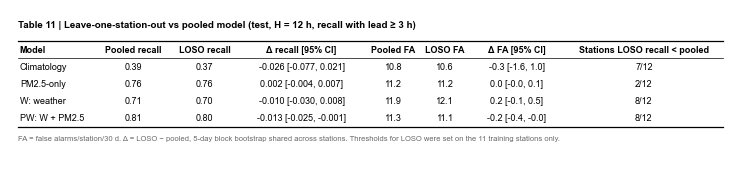

[saved] table11_rq5_loso (4 rows)
LOSO PW: W + PM2.5 − LOSO climatology (recall): 0.432 [0.342, 0.528]


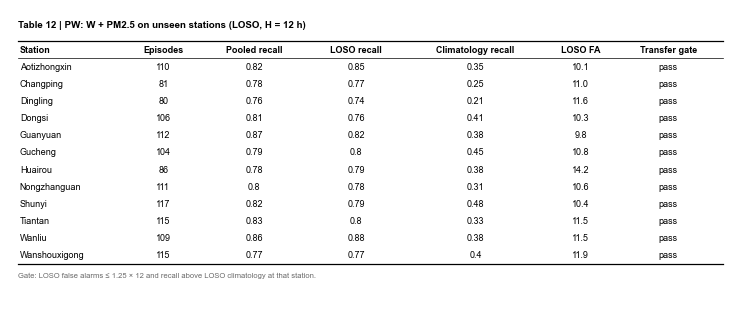

[saved] table12_rq5_stations (12 rows)
Trạm đạt cổng chuyển giao: 12/12


In [42]:
# ---- LOSO so với mô hình gộp: gộp 12 trạm (KTC) và theo trạm ----
BWL = make_W(cD, NBOOT, seed=31)
POOL_S = {k: TD["S_te"][k] for k in LO_NAMES}; POOL_T = {k: thrD.get(k) for k in LO_NAMES}
if POOL_T["climatology"] is None: POOL_T["climatology"] = thrD["climatology"]
BL_ = {k: boot(cD, LS[k], LT[k], BWL, kmin=KD) for k in LO_NAMES}
BP_ = {k: boot(cD, POOL_S[k], POOL_T[k], BWL, kmin=KD) for k in LO_NAMES}
def per_station(S, TH, kmin):
    rows = {}
    for s in range(N_ST):
        mk = (cD.st == s); E, fa, det, lead = alarms(cD, S, TH)
        a = (cD.keys[E] // 100000) == s; e = cD.ep_st == s
        rows[s] = dict(n_ep=int(e.sum()), recall=(det & (lead >= kmin))[e].sum() / max(e.sum(), 1),
                       fa=fa[a].sum() / (SPLIT_DAYS["test"] / 30), lead=float(np.median(lead[e & det])) if (e & det).any() else np.nan)
    return pd.DataFrame(rows).T
PS = {k: (per_station(LS[k], LT[k], KD), per_station(POOL_S[k], np.full(len(cD.y), POOL_T[k]), KD)) for k in LO_NAMES}
rows = []
for k in LO_NAMES:
    dr, dfa = BL_[k]["recall"] - BP_[k]["recall"], BL_[k]["fa"] - BP_[k]["fa"]
    rows.append({"Model": LAB[k], "Pooled recall": f"{BP_[k]['recall'][0]:.2f}", "LOSO recall": f"{BL_[k]['recall'][0]:.2f}",
                 "Δ recall [95% CI]": ci_str(dr, 3), "Pooled FA": f"{BP_[k]['fa'][0]:.1f}", "LOSO FA": f"{BL_[k]['fa'][0]:.1f}",
                 "Δ FA [95% CI]": ci_str(dfa, 1),
                 "Stations LOSO recall < pooled": f"{int((PS[k][0].recall < PS[k][1].recall - 1e-9).sum())}/12"})
T7 = pd.DataFrame(rows)
save_table(T7, "table11_rq5_loso", f"Table 11 | Leave-one-station-out vs pooled model (test, H = {DEP_H} h, recall with lead ≥ {KD} h)",
           "FA = false alarms/station/30 d. Δ = LOSO − pooled, 5-day block bootstrap shared across stations. Thresholds for LOSO were set on the 11 training stations only.")
dl = BL_[DEP_M]["recall"] - BL_["climatology"]["recall"]
print(f"LOSO {LAB[DEP_M]} − LOSO climatology (recall): {ci_str(dl, 3)}")
# cổng chuyển giao cho từng trạm
tg = PS[DEP_M][0].copy(); tgc = PS["climatology"][0]
tg["pass"] = (tg.fa <= 1.25 * DEPLOY["BUDGET"]) & (tg.recall > tgc.recall)
T9 = pd.DataFrame({"Station": [SID_NAME[s] for s in tg.index], "Episodes": tg.n_ep.astype(int),
                   "Pooled recall": PS[DEP_M][1].recall.round(2).values, "LOSO recall": tg.recall.round(2).values,
                   "Climatology recall": tgc.recall.round(2).values, "LOSO FA": tg.fa.round(1).values,
                   "Transfer gate": np.where(tg["pass"], "pass", "fail")})
save_table(T9, "table12_rq5_stations", f"Table 12 | {LAB[DEP_M]} on unseen stations (LOSO, H = {DEP_H} h)",
           f"Gate: LOSO false alarms ≤ 1.25 × {DEPLOY['BUDGET']} and recall above LOSO climatology at that station.")
print(f"Trạm đạt cổng chuyển giao: {int(tg['pass'].sum())}/12")

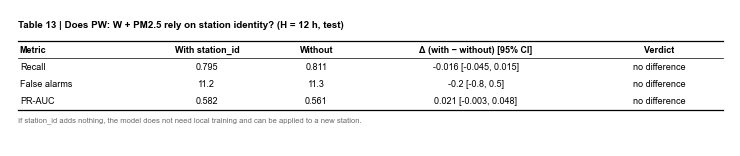

[saved] table13_station_id (3 rows)
  H=24 trạm Aotizhongxin   xong
  H=24 trạm Changping      xong
  H=24 trạm Dingling       xong
  H=24 trạm Dongsi         xong
  H=24 trạm Guanyuan       xong
  H=24 trạm Gucheng        xong
  H=24 trạm Huairou        xong
  H=24 trạm Nongzhanguan   xong
  H=24 trạm Shunyi         xong
  H=24 trạm Tiantan        xong
  H=24 trạm Wanliu         xong
  H=24 trạm Wanshouxigong  xong
LOSO H=24: 35s


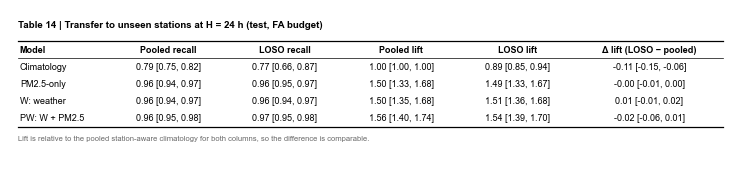

[saved] table14_loso_H24 (4 rows)


In [43]:
# ---- (i) station_id; (ii) H = 24 ----
FEATS["_sid"] = FEATS[DEP_M] + ["station_id"]
prm = {a: TD["best"][DEP_M][a] for a in ["num_leaves", "min_child_samples"]} if DEP_M != "pm25_only" else dict(num_leaves=7, min_child_samples=200)
m_sid = fit_lgb(FEATS["_sid"], prm, TD["tr"], TD["va"])
sv, st_ = m_sid.predict(TD["va"][FEATS["_sid"]], num_iteration=m_sid.best_iteration), m_sid.predict(TD["te"][FEATS["_sid"]], num_iteration=m_sid.best_iteration)
thr_sid = thr_budget(sweep(TD["ctx_va"], sv), "det3")
b_sid = boot(cD, st_, thr_sid, BWL, kmin=KD)
rows = []
for met, nm, dd in [("recall", "Recall", 3), ("fa", "False alarms", 1), ("pr_auc", "PR-AUC", 3)]:
    d = b_sid[met] - BP_[DEP_M][met]; lo, hi = ci(d)
    rows.append({"Metric": nm, "With station_id": f"{b_sid[met][0]:.{dd}f}", "Without": f"{BP_[DEP_M][met][0]:.{dd}f}",
                 "Δ (with − without) [95% CI]": ci_str(d, dd), "Verdict": "no difference" if lo <= 0 <= hi else ("with" if d[0] > 0 else "without")})
T10 = pd.DataFrame(rows)
save_table(T10, "table13_station_id", f"Table 13 | Does {LAB[DEP_M]} rely on station identity? (H = {DEP_H} h, test)",
           "If station_id adds nothing, the model does not need local training and can be applied to a new station.")
 
H24_NAMES = ["climatology", "pm25_only", "GB_W", "GB_PW"]; ensure(24, H24_NAMES[1:])
t0_ = time.time(); LS24, LT24 = loso(24, H24_NAMES, "det1"); print(f"LOSO H=24: {time.time() - t0_:.0f}s")
T24 = TRAINED[24]; c24 = T24["ctx_te"]; BW24 = make_W(c24, NBOOT, seed=31)
BL24 = {k: boot(c24, LS24[k], LT24[k], BW24, kmin=1) for k in H24_NAMES}
BP24 = {k: boot(c24, T24["S_te"][k], thr_budget(sweep(T24["ctx_va"], T24["S_va"][k]), "det1"), BW24, kmin=1) for k in H24_NAMES}
rows = []
for k in H24_NAMES:
    den = BP24["climatology"]["pr_auc"]                    # cùng một mẫu số: climatology biết trạm
    lift_l, lift_p = BL24[k]["pr_auc"] / den, BP24[k]["pr_auc"] / den
    rows.append({"Model": LAB[k], "Pooled recall": ci_str(BP24[k]["recall"]), "LOSO recall": ci_str(BL24[k]["recall"]),
                 "Pooled lift": ci_str(lift_p), "LOSO lift": ci_str(lift_l), "Δ lift (LOSO − pooled)": ci_str(lift_l - lift_p)})
T11 = pd.DataFrame(rows)
save_table(T11, "table14_loso_H24", "Table 14 | Transfer to unseen stations at H = 24 h (test, FA budget)",
           "Lift is relative to the pooled station-aware climatology for both columns, so the difference is comparable.")

[saved] fig10_rq5_loso: 183 x 64 mm (limit 183 x 170 mm)


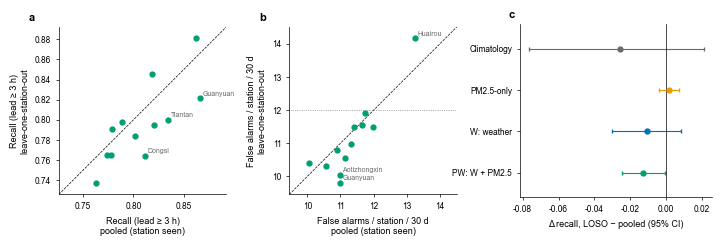

In [44]:
# ---- Fig 10 ----
fig = fig_mm(183, 64)
gs = grid_mm(fig, 183, 64, 1, 3, l=13, r=4, t=7, b=13, wsp=16, hsp=0, width_ratios=[1, 1, 1.15])
for k, (met, nm) in enumerate([("recall", f"Recall (lead ≥ {KD} h)"), ("fa", "False alarms / station / 30 d")]):
    ax = fig.add_subplot(gs[k]); plab(ax, "ab"[k], dx=-22)
    x, y = PS[DEP_M][1][met].values.astype(float), PS[DEP_M][0][met].values.astype(float)
    lo_, hi_ = min(x.min(), y.min()), max(x.max(), y.max()); pad = (hi_ - lo_) * 0.08 + 1e-6
    ax.plot([lo_ - pad, hi_ + pad], [lo_ - pad, hi_ + pad], color="black", lw=0.5, ls="--", zorder=1)
    ax.plot(x, y, "o", color=MC[DEP_M], ms=3.5, zorder=2)
    ax.set_xlim(lo_ - pad, hi_ + pad); ax.set_ylim(lo_ - pad, hi_ + pad); ax.set_aspect("equal", adjustable="box")   # shared limits
    for j in np.argsort(-np.abs(y - x))[:3]:                       # name only the 3 stations farthest from the diagonal
        ax.annotate(SID_NAME[tg.index[j]], (x[j], y[j]), xytext=(2, 2), textcoords="offset points", fontsize=FS - 1.5, color=GREY)
    if met == "fa": ax.axhline(DEPLOY["BUDGET"], color=GREY, lw=0.5, ls=":")
    ax.set_xlabel(f"{nm}\npooled (station seen)"); ax.set_ylabel(f"{nm}\nleave-one-station-out")
ax = fig.add_subplot(gs[2]); plab(ax, "c", dx=-8)
for i, k in enumerate(LO_NAMES):
    d = BL_[k]["recall"] - BP_[k]["recall"]; lo, hi = ci(d)
    ax.errorbar(d[0], i, xerr=[[d[0] - lo], [hi - d[0]]], fmt="o", color=MC[k], ms=3.5, lw=0.8, capsize=1.5)
ax.axvline(0, color="black", lw=0.5); ax.set_yticks(range(len(LO_NAMES))); ax.set_yticklabels([LAB[k] for k in LO_NAMES])
ax.set_ylim(len(LO_NAMES) - 0.4, -0.6)                              # padding so the last row clears the axis
ax.set_xlabel("Δ recall, LOSO − pooled (95% CI)")
save_fig(fig, "fig10_rq5_loso")

dl10 = BL_[DEP_M]["recall"] - BP_[DEP_M]["recall"]; lo10, hi10 = ci(dl10)
CAPS["Fig. 10"] = (
    f"Fig. 10 | Unseen stations lose little: leave-one-station-out (LOSO) recall differs from the pooled model by "
    f"{dl10[0]:+.3f} [{lo10:+.3f}, {hi10:+.3f}]{' (small but detectable)' if hi10 < 0 else ''}, and "
    f"{int(tg['pass'].sum())}/{N_ST} stations pass the transfer gate. "
    f"a, b, one point per station: pooled model (trained with that station) against LOSO model (station held out); "
    f"dashed line, no loss; only the three stations farthest from the line are named. "
    f"c, LOSO − pooled recall difference per model (95% CI, {BLOCK_DAYS}-day block bootstrap, {NBOOT} resamples). "
    f"{LAB[DEP_M]}, H = {DEP_H} h, test year, recall with lead ≥ {KD} h; n = {cD.n_ep} episodes, {N_ST} stations. "
    f"FA, false alarms; transfer gate: LOSO FA ≤ 1.25 × budget ({DEPLOY['BUDGET']}) and recall above LOSO climatology at that station.")

[saved] fig11_cases: 183 x 86 mm (limit 183 x 170 mm)


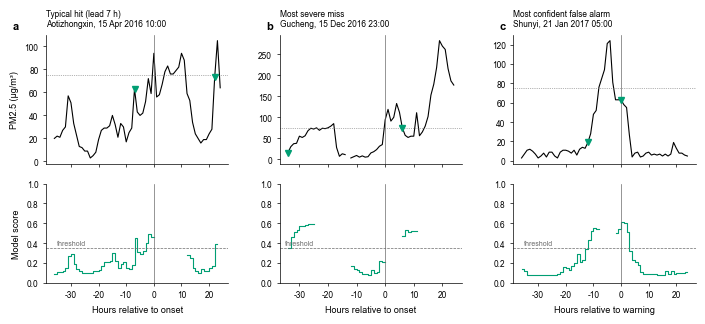

In [45]:
# ---- Fig 11 – case review (typical hit, most severe miss, most confident false alarm) ----
S_dep, thr_dep = TD["S_te"][DEP_M], thrD[DEP_M]
E, fa, det, lead = alarms(cD, S_dep, thr_dep)
useful = det & (lead >= KD)
alarm_keys = set(cD.keys[E].tolist())
OFFS = np.arange(-36, 25)                                          # hours relative to the reference hour
hr_of = lambda k: int(k % 100000); st_of = lambda k: int(k // 100000)

# rule 1: typical hit = useful detection whose lead is closest to the median useful lead (ties: first in station-time order)
iu = np.flatnonzero(useful)
i_tp = iu[np.argmin(np.abs(lead[iu] - np.median(lead[iu])))]
# rule 2: most severe miss = episode with no warning, a fully observed 24 h after onset, and the highest PM2.5 in that window
im = np.flatnonzero(~det)
if len(im) == 0: im = np.flatnonzero(~useful)                       # fallback: no warning with lead >= KD
win24 = [panel[SID_NAME[st_of(cD.kon[i])]][TARGET].iloc[hr_of(cD.kon[i]):hr_of(cD.kon[i]) + 25] for i in im]
peak = np.array([w.max() for w in win24])
ok24 = np.array([w.notna().all() and len(w) == 25 for w in win24])
i_fn = im[int(np.nanargmax(np.where(ok24, peak, np.nan)))]
# rule 3: most confident false alarm = false warning with the highest model score
jf = np.flatnonzero(fa)
j_fp = E[jf[np.argmax(S_dep[E[jf]])]]

cases = [(f"Typical hit (lead {int(lead[i_tp])} h)", int(cD.kon[i_tp]), "onset"),
         ("Most severe miss", int(cD.kon[i_fn]), "onset"),
         ("Most confident false alarm", int(cD.keys[j_fp]), "warning")]

fig = fig_mm(183, 86)
gs = grid_mm(fig, 183, 86, 2, 3, l=14, r=4, t=11, b=12, wsp=13, hsp=5, height_ratios=[1.3, 1])
for c, (name, k, ref) in enumerate(cases):
    st, hr0 = st_of(k), hr_of(k)
    ts0 = FULL_START + pd.Timedelta(hours=hr0)
    pm_w = panel[SID_NAME[st]][TARGET].reindex(pd.date_range(ts0 - pd.Timedelta(hours=36), ts0 + pd.Timedelta(hours=24), freq="h")).values
    keys = st * 100000 + hr0 + OFFS
    idx = np.minimum(np.searchsorted(cD.keys, keys), len(cD.keys) - 1)
    sc = np.where(cD.keys[idx] == keys, S_dep[idx], np.nan)         # score exists only for eligible (clean) hours
    al = np.array([kk in alarm_keys for kk in keys])
    ax1 = fig.add_subplot(gs[0, c]); ax2 = fig.add_subplot(gs[1, c], sharex=ax1)
    plab(ax1, "abc"[c], dx=-24 if c == 0 else -10)
    ax1.plot(OFFS, pm_w, color="black", lw=0.8)
    ax1.axhline(CFG["THETA"], color=GREY, lw=0.5, ls=":"); ax1.axvline(0, color=GREY, lw=0.5)
    ax1.plot(OFFS[al], pm_w[al], "v", color=MC[DEP_M], ms=4)       # warnings
    ax1.set_title(f"{name}\n{SID_NAME[st]}, {ts0:%d %b %Y %H:%M}", fontsize=FS - 0.5, loc="left")
    ax1.tick_params(labelbottom=False)
    ax2.step(OFFS, sc, where="post", color=MC[DEP_M], lw=0.8)
    ax2.axhline(thr_dep, color=GREY, lw=0.5, ls="--"); ax2.axvline(0, color=GREY, lw=0.5)
    ax2.text(OFFS[0] + 1, thr_dep + 0.02, "threshold", fontsize=FS - 1.5, color=GREY, va="bottom")
    ax2.set_ylim(0, 1); ax2.set_xlabel(f"Hours relative to {ref}")
    if c == 0: ax1.set_ylabel("PM2.5 (µg/m³)"); ax2.set_ylabel("Model score")
save_fig(fig, "fig11_cases")

n_miss, n_fa = int((~det).sum()), int(fa.sum())
CAPS["Fig. 11"] = (
    f"Fig. 11 | The deployed model ({LAB[DEP_M]}, H = {DEP_H} h) warns a median {LEADD[DEP_M]:.0f} h before onset in detected episodes, "
    f"but {n_miss} of {cD.n_ep} test episodes ({n_miss / cD.n_ep * 100:.0f}%) receive no warning and {n_fa} warnings "
    f"({n_fa / cD.n_units:.1f} per station per 30 d) are false. "
    f"a, typical hit: useful detection whose lead is closest to the median useful lead. "
    f"b, most severe miss: episode with no warning, a fully observed 24 h after onset, and the highest PM2.5 in that window. "
    f"c, most confident false alarm: false warning with the highest score. "
    f"Top, hourly PM2.5 (dotted, {CFG['THETA']} µg/m³; triangles, warnings); bottom, model score (dashed, validation threshold). "
    f"Cases are chosen by these rules, not by appearance; ties go to the first in station–time order. "
    f"A warning is false if no valid onset follows within H h. Test year, {N_ST} stations.")

## 11. Kết lu

In [46]:
print("=== RQ4 ===")
print(f"Pre-specified (B vs PM2.5-only, H={Hm}): {'ĐẠT' if okp else 'KHÔNG ĐẠT'}")
for H in CFG["H_LIST"]:
    d = RESH[H]["r"]["GB_W"]["b"]["pr_auc"] / RESH[H]["r"]["climatology"]["b"]["pr_auc"]
    print(f"  Thời tiết (W) so với climatology, H={H:>2}: lift {ci_str(d, 2)}")
print(f"Mô hình chọn: {LAB[DEP_M]}, H={DEP_H} h | recall(lead>={KD}h) {ci_str(BD[DEP_M]['recall'], 3)} | FA {ci_str(BD[DEP_M]['fa'], 1)} /trạm/30 ngày | "
      f"lead trung vị {LEADD[DEP_M]:.0f} h | cổng: {sum(GATE.values())}/3")
print("=== RQ5 ===")
print(f"LOSO − gộp (recall) cho {LAB[DEP_M]}: {ci_str(BL_[DEP_M]['recall'] - BP_[DEP_M]['recall'], 3)}; trạm đạt cổng chuyển giao: {int(tg['pass'].sum())}/12")
print("station_id:", "; ".join(f"{r.Metric}: {r.Verdict}" for r in T10.itertuples()))
with open(os.path.join(OUT_DIR, "captions_rq45.md"), "w", encoding="utf-8") as f:
    for k, v in CAPS.items(): f.write(f"**{v}**\n\n")
print("Đã lưu hình/bảng/captions/model vào", OUT_DIR)

=== RQ4 ===
Pre-specified (B vs PM2.5-only, H=6): KHÔNG ĐẠT
  Thời tiết (W) so với climatology, H= 1: lift 2.53 [2.05, 3.22]
  Thời tiết (W) so với climatology, H= 3: lift 2.08 [1.69, 2.58]
  Thời tiết (W) so với climatology, H= 6: lift 1.92 [1.60, 2.32]
  Thời tiết (W) so với climatology, H=12: lift 1.62 [1.40, 1.88]
  Thời tiết (W) so với climatology, H=24: lift 1.50 [1.34, 1.68]
Mô hình chọn: PW: W + PM2.5, H=12 h | recall(lead>=3h) 0.811 [0.774, 0.844] | FA 11.3 [9.7, 13.0] /trạm/30 ngày | lead trung vị 6 h | cổng: 3/3
=== RQ5 ===
LOSO − gộp (recall) cho PW: W + PM2.5: -0.013 [-0.025, -0.001]; trạm đạt cổng chuyển giao: 12/12
station_id: Recall: no difference; False alarms: no difference; PR-AUC: no difference
Đã lưu hình/bảng/captions/model vào outputs
